<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQSVMVQC_IntrusionSpam_Zhu2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid MLP + QSVM / VQC for intrusion and spam detection: Zhu, Chen and Li (2026) step by step

**Paper.** Zirui Zhu, Zisheng Chen and Xiangyang Li (Information Security Institute, Johns Hopkins University),
*"Quantum Machine Learning for Cybersecurity Applications: Simulation and Hardware Validation"*,
arXiv:2609.32911 [quant-ph], 26 September 2026. <https://arxiv.org/abs/2609.32911>

**What this notebook does.** It rebuilds the paper's *attribution-safe* pipeline on two public datasets,
NSL-KDD (network intrusion detection) and Ling-Spam (spam filtering):

1. a compact MLP encoder squeezes every input into a unit-norm vector `u` with `q` coordinates (`q` = 2 or 4);
2. the *same* `u` is given to four decision layers: a matched **linear head**, a **fidelity-kernel QSVM** (ZZ feature map,
   compute-uncompute circuit, 1,024 shots, depolarizing noise 1e-3 / 1e-2), a **data re-uploading VQC**, and extra classical
   heads (RBF-SVM, random forest, a parameter-matched tiny MLP) that the paper does not report but that make the comparison honest;
3. it re-draws the paper's Table I and Table II, runs a **simulated stand-in for the IBM-hardware test** (Table III) on a
   Qiskit fake backend, re-runs the Ling-Spam **adversarial stress tests** (Table IV), and ends with a per-claim verdict.

**How to run.** Open in Google Colab, choose a **CPU** runtime and press *Runtime -> Run all*. The committed copy of this notebook was
executed with `FAST_MODE = False` (the full budget: reference set of 1,000, the complete 22,544-row `KDDTest+`, 5 repeats; **26 minutes** on
a local Windows PC; Colab's free CPU runtime has fewer cores and will take longer, not measured here). Set `FAST_MODE = True` in the configuration cell for a
class-demo run (reference set of 300, a 4,000-row subset of `KDDTest+`, 3 repeats; **16 minutes** locally). No GPU, no account and no API
key are needed. The IBM-hardware cell runs only if you put your own IBM Quantum token in `IBM_TOKEN`.

**What you get at the end.** Class plots and 2-D scatter plots of the real data, drawings of every circuit that is executed,
Tables I-IV recomputed next to the paper's numbers, a table of verdicts (reproduced / not reached / exceeded / cannot be
checked), and a critical reading including a data-leakage audit of the Ling-Spam protocol.

## The paper in one page

**Problem.** Under tight feature and compute budgets, classical detectors lose accuracy on *near-decision-boundary* events.
Do tiny quantum decision layers help, and does the advantage survive device noise and adversarial inputs?

**Decision.** Binary: *benign vs malicious* (NSL-KDD: normal vs any attack; Ling-Spam: ham vs spam). Positive class = attack / spam.

**Method.**
- *Shared front end.* Preprocessing and a compact MLP encoder `f(x) = u in R^q`, `||u||_2 = 1` (q in {2, 4}); trained at most 25 epochs,
  batch 256, lr 1e-3, weight decay 1e-4, dropout 0.15, early-stopping patience 8, balanced class weights.
- *Classical head:* `sigmoid(w.u + b)` (the matched baseline).
- *Quantum head A, QSVM:* angles `theta_i = pi * u_i`, `ZZFeatureMap`, kernel `k(u, v) = |<phi(u)|phi(v)>|^2` estimated with the
  compute-uncompute circuit (probability of the all-zero string), Gram matrix **double-centred** on the training set (and
  out-of-sample centred with training statistics), classical SVM on the precomputed kernel.
- *Quantum head B, VQC:* L data re-uploading blocks `U(u; w) = prod_l U_ans(w_l) U_feat(u)`, a shallow TwoLocal-style ansatz
  (single-qubit rotations + linear/ring CNOTs), readout `<Z>` of one qubit, `y = sigmoid(alpha*z + beta)`.
- *Noise model:* Qiskit Aer, **1,024 shots**, depolarizing error **1e-3 (1 qubit) / 1e-2 (2 qubits)**.
- *Hardware:* the best 4-qubit QSVM (frozen) is evaluated on IBM Quantum with M3 readout mitigation and XY8 dynamical
  decoupling on a **stratified 100-sample subset** of the test set (not reproducible here without hardware access).

**Data.** NSL-KDD: `KDDTrain+` split stratified into train / validation, `KDDTest+` held out; numeric features standardised,
categorical features rare-bucketed and one-hot encoded; balanced class weights. Ling-Spam: `lingspam_public`
(`spmsg*` = spam), stratified train / validation / test, TF-IDF (lowercase, English stop words, document-frequency filters).

**Claims checked here.** Table I (NSL-KDD, 5 models x 4 metrics), Table II (Ling-Spam, 5 x 4), Table III (hardware, 2 x 4),
Table IV (seven Ling-Spam attacks, accuracy and spam-F1 drops), and the qualitative statements: QSVM q=4 is the best
head, QSVM gains from q=2 to q=4, VQC degrades at q=4 on NSL-KDD, quantum heads reduce misses / false alarms near the decision
boundary, the combined attack hurts most.

## What follows the paper and what had to be chosen

The paper is a six-page letter: many settings are not given. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Datasets | NSL-KDD (`KDDTrain+` / `KDDTest+`), Ling-Spam (`lingspam_public`) | the same, downloaded from public mirrors (GitHub mirror of NSL-KDD, official AUEB server for Ling-Spam) |
| NSL-KDD split | train / validation stratified from `KDDTrain+`, `KDDTest+` held out; ratio not given | 80 / 20 stratified, `KDDTest+` held out (full file in the full run, a stratified subset in FAST mode) |
| Ling-Spam split | stratified train / val / test, ratio not given; the stress-test set has n = 2,315 | 60 / 20 / 20 stratified over **all four released variants pooled** (11,572 e-mails), which gives exactly n_test = 2,315 (see the leakage audit) |
| Label | benign vs malicious | binary, attack / spam = 1 |
| Categorical NSL-KDD fields | rare-bucketed (threshold not given), one-hot | rarer than 100 training rows -> one bucket; one-hot; standardised values clipped to +-10 (CHOICE) |
| TF-IDF | lowercase, English stop words, df filters | 2,000 unigrams, min_df = 3, sublinear tf (CHOICE) |
| MLP encoder | compact, unit-norm output; training hyper-parameters given | 64-32 hidden ReLU units (CHOICE), joint training with the linear head, the given hyper-parameters |
| Classical head | linear / logistic on `u` | the encoder's own jointly trained linear head; plus RBF-SVM, random forest and a parameter-matched tiny MLP (extras) |
| QSVM feature map | ZZFeatureMap, depth r not given | `zz_feature_map(q, reps=2, entanglement="linear")` (CHOICE) |
| Kernel estimation | compute-uncompute, p(0^q), 1,024 shots, depolarizing 1e-3 / 1e-2 | the same circuit; noise on the native `sx`, `x` and `cx` gates, `rz` is virtual and noiseless (CHOICE) |
| Reference set | "bounded, stratified"; size not given | stratified random sample of the training partition (size in the configuration cell) |
| SVM | classical SVM on centred precomputed kernel | `SVC(kernel="precomputed", class_weight="balanced")`, C in {0.1, 1, 10, 100} chosen on validation |
| Operating threshold | selected on validation | threshold on the decision score that maximises validation macro-F1, for every head |
| VQC | L re-uploading blocks, TwoLocal-style ansatz, `<Z>` readout | L = 3 blocks (CHOICE), RY(theta_i) encoding, RY+RZ rotations, linear CNOT chain, `<Z>` of qubit 0, trainable alpha and beta |
| VQC training | cross-entropy, validation early stopping, shot noise part of the model | Adam (lr 0.05), exact gradients of the ideal circuit plus Gaussian shot noise on `<Z>`; evaluation with the noisy shot-based simulator |
| Hardware | IBM device, M3, XY8, 100-sample subset | **cannot be reproduced**: Qiskit `FakeSherbrooke` noise model (+ a simple readout-error inversion as an M3 stand-in) on a stratified 100-sample subset |
| Robustness | seven attacks, parameters given; epsilon space not stated | text attacks as described; FGSM / PGD act on the pre-normalisation q-dimensional embedding (CHOICE) |
| Seeds | not stated | `SEED = 42`; repeats use seeds 42, 43, ... |

In [1]:
import sys, importlib.util, subprocess
IN_COLAB = "google.colab" in sys.modules
_NEED = ["qiskit", "qiskit_aer", "qiskit_ibm_runtime", "torch", "sympy", "pylatexenc"]
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in _NEED):
    # pinned to the versions this notebook was tested with (Colab already ships numpy, pandas, scikit-learn, matplotlib, torch)
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-aer==0.17.2",
                    "qiskit-ibm-runtime==0.50.0", "pylatexenc", "sympy"], check=True)
    print("installed; if the next cells fail to import, restart the runtime once (Runtime -> Restart session) and run again")
else:
    print("all required packages are already present; nothing was installed")

all required packages are already present; nothing was installed


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False          # True: about 10-25 min on a CPU.  False: larger reference sets, full KDDTest+, more repeats (about 60-90 min)
SEED      = 42            # CHOICE: the paper does not state a seed
Q_LIST    = [2, 4]        # paper: q in {2, 4}
SHOTS     = 1024          # paper: 1,024 shots
P1, P2    = 1e-3, 1e-2    # paper: depolarizing error probabilities for 1- and 2-qubit gates
ZZ_REPS   = 2             # CHOICE: ZZ feature-map depth r (paper: "shallow", r not given)
VQC_BLOCKS = 3            # CHOICE: number of data re-uploading blocks L (paper: "small L")
HIDDEN    = (64, 32)      # CHOICE: hidden widths of the compact MLP encoder
ENC_BATCH, ENC_LR, ENC_WD, ENC_DROPOUT, ENC_PATIENCE = 256, 1e-3, 1e-4, 0.15, 8     # paper
VAL_FRACTION   = 0.20     # CHOICE: share of KDDTrain+ used as validation partition
RARE_MIN_COUNT = 100      # CHOICE: categorical values with fewer training rows go into one 'rare' bucket
TFIDF_MAX_FEATURES, TFIDF_MIN_DF = 2000, 3     # CHOICE
C_GRID    = [0.1, 1.0, 10.0, 100.0]   # CHOICE: SVM regularisation candidates, picked on the validation split
VQC_LR, VQC_PATIENCE = 0.05, 15       # CHOICE: Adam learning rate and early-stopping patience for the VQC
PGD_STEPS = 10            # paper: PGD with 10 steps

if FAST_MODE:
    ENC_MAX_EPOCHS_KDD, ENC_MAX_EPOCHS_LS = 10, 25    # paper: at most 25 epochs
    N_REF, N_VAL      = 300, 300      # CHOICE: QSVM reference-set size and validation rows (kernel evaluations: N_REF^2/2 + (N_VAL + N_TEST) * N_REF)
    N_TEST_KDD        = 4000          # stratified subset of KDDTest+ (None = all 22,544 rows)
    VQC_EPOCHS, VQC_TRAIN = 40, 2000  # CHOICE
    N_REPEATS         = 3             # repeats with seeds SEED, SEED+1, ...
    HW_N_REF, HW_N_TEST = 24, 40      # fake-backend stand-in for the hardware test (paper: 100 test samples)
else:
    ENC_MAX_EPOCHS_KDD, ENC_MAX_EPOCHS_LS = 25, 25
    N_REF, N_VAL      = 1000, 1000
    N_TEST_KDD        = None
    VQC_EPOCHS, VQC_TRAIN = 100, 4000
    N_REPEATS         = 5
    HW_N_REF, HW_N_TEST = 40, 100

DATA_DIR  = "data"        # downloaded files are cached here (a folder next to the notebook / in the Colab session)
IBM_TOKEN = ""            # optional: your own IBM Quantum API token enables the real-hardware cell (skipped when empty)
print("FAST_MODE =", FAST_MODE, "| N_REF =", N_REF, "| N_VAL =", N_VAL, "| N_TEST_KDD =", N_TEST_KDD,
      "| VQC epochs / train rows =", VQC_EPOCHS, "/", VQC_TRAIN, "| repeats =", N_REPEATS)

FAST_MODE = False | N_REF = 1000 | N_VAL = 1000 | N_TEST_KDD = None | VQC epochs / train rows = 100 / 4000 | repeats = 5


In [3]:
import os, io, re, time, math, tarfile, random, warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn, scipy, sympy
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix)
import qiskit, qiskit_aer, qiskit_ibm_runtime
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error
import qiskit_aer.library          # registers QuantumCircuit.save_probabilities

os.makedirs(DATA_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(1)
rng_main = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| torch", torch.__version__, "| sympy", sympy.__version__)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | sympy 1.14.0
qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-ibm-runtime 0.50.0


### A vectorised simulator that is *asserted equal* to the real Qiskit / Aer circuits

The paper's QSVM needs `N_REF^2/2 + (N_VAL + N_TEST) * N_REF` noisy compute-uncompute circuits per configuration, each with
1,024 shots: tens of thousands to millions of Aer jobs, far beyond a class demo (Aer needs roughly 50 ms per noisy 4-qubit
circuit on a CPU). We therefore use an **exact** trick that gives the same numbers as running every circuit:

* The circuit is `U(u)` followed by `U(v)^dagger`, with data-independent noise after every native gate. Noise does not depend on
  the data, so the output probability is *linear* in the state: `p(u, v) = Tr[E_v rho_u]`, where `rho_u` is the noisy density
  matrix after the compute half and `E_v` is the adjoint noisy channel of the uncompute half applied to `|0..0><0..0|`.
* Both objects are 16 x 16 matrices (q = 4) and are computed once per sample, so all pairs cost one matrix product.
* Finite shots are exact too: the all-zero count of a shot-based run is Binomial(1024, p), so we sample it directly.

The gate list is **extracted from the transpiled Qiskit circuit** (native gates `rz, sx, x, cx`), and a later cell asserts that the
simulator agrees with Aer's density-matrix simulation of the real circuits to ~1e-12 and with `Statevector` overlaps without noise.

In [4]:
import numpy as np, sympy, math
from qiskit import QuantumCircuit, transpile

BASIS_GATES = ["rz", "sx", "x", "cx"]          # native gate set used for every executed circuit
SX = 0.5 * np.array([[1 + 1j, 1 - 1j], [1 - 1j, 1 + 1j]])


def extract_gate_list(tc):
    """Turn a transpiled (parametrised) Qiskit circuit into a list of ops for the vectorised simulator.
    rz angles become vectorised functions of the circuit parameters; every other gate is constant."""
    params = list(tc.parameters)
    syms = [sympy.Symbol(p.name) for p in params]
    ops = []
    for inst in tc.data:
        name = inst.operation.name
        qs = [tc.find_bit(b).index for b in inst.qubits]
        if name == "rz":
            ang = inst.operation.params[0]
            if hasattr(ang, "parameters") and len(ang.parameters) > 0:
                f = sympy.lambdify(syms, ang.sympify(), "numpy")
                used = {p.name for p in ang.parameters}
                ops.append(("rz", qs[0], f, used))
            else:
                ops.append(("rz", qs[0], float(ang), set()))
        elif name in ("sx", "x"):
            ops.append((name, qs[0]))
        elif name == "cx":
            ops.append(("cx", qs[0], qs[1]))
        elif name in ("barrier", "measure"):
            continue
        else:
            raise ValueError("gate outside the native set: " + name)
    return params, ops


def _perm_x(q, k):
    d = 2 ** q
    idx = np.arange(d)
    return idx ^ (1 << (q - 1 - k))


def _perm_cx(q, c, t):
    d = 2 ** q
    idx = np.arange(d)
    ctrl = (idx >> (q - 1 - c)) & 1
    return np.where(ctrl == 1, idx ^ (1 << (q - 1 - t)), idx)


def _ap_mat(r2, U, k, q):
    B = r2.shape[0]
    r = r2.reshape((B,) + (2,) * (2 * q))
    r = np.moveaxis(np.tensordot(U, r, axes=([1], [1 + k])), 0, 1 + k)
    r = np.moveaxis(np.tensordot(U.conj(), r, axes=([1], [1 + q + k])), 0, 1 + q + k)
    return np.ascontiguousarray(r).reshape(B, 2 ** q, 2 ** q)


def _ap_rz(r2, ang, k, q):
    B = r2.shape[0]
    ang = np.broadcast_to(np.asarray(ang, dtype=float), (B,))
    d = np.stack([np.exp(-0.5j * ang), np.exp(0.5j * ang)], axis=1)           # (B, 2)
    f = d[:, :, None] * d[:, None, :].conj()                                    # (B, 2, 2)
    shp = [B] + [1] * (2 * q)
    shp[1 + k] = 2
    shp[1 + q + k] = 2
    r = r2.reshape((B,) + (2,) * (2 * q)) * f.reshape(shp)
    return r.reshape(B, 2 ** q, 2 ** q)


def _ap_perm(r2, perm):
    return r2[:, perm][:, :, perm]


def _depol(r2, ks, lam, q):
    """E(rho) = (1-lam) rho + lam Tr_ks(rho) (x) I/2^n   (Qiskit's depolarizing_error(lam, n))."""
    B = r2.shape[0]
    n = len(ks)
    r = r2.reshape((B,) + (2,) * (2 * q))
    ket = [1 + k for k in ks]
    bra = [1 + q + k for k in ks]
    rest_ket = [a for a in range(1, q + 1) if a not in ket]
    rest_bra = [a + q for a in rest_ket]
    order = [0] + rest_ket + rest_bra + ket + bra
    rt = np.transpose(r, order)
    shp = rt.shape
    dk, dr = 2 ** n, 2 ** (q - n)
    rr = rt.reshape(B, dr, dr, dk, dk)
    tr = np.einsum("bxyii->bxy", rr)
    new = (1 - lam) * rr + lam * tr[:, :, :, None, None] * (np.eye(dk) / dk)
    out = np.transpose(new.reshape(shp), np.argsort(order))
    return np.ascontiguousarray(out).reshape(B, 2 ** q, 2 ** q)


def _angles(op, P):
    f = op[2]
    if callable(f):
        return f(*[P[:, i] for i in range(P.shape[1])])
    return f


def _events(ops, q, p1, p2):
    """Gate list -> list of (kind, payload) with a depolarizing event after sx / x / cx (rz is virtual, noiseless)."""
    ev = []
    for op in ops:
        n = op[0]
        if n == "rz":
            ev.append(("rz", op))
        elif n == "sx":
            ev.append(("sx", op[1]))
            if p1 > 0: ev.append(("dep", ([op[1]], p1)))
        elif n == "x":
            ev.append(("x", op[1]))
            if p1 > 0: ev.append(("dep", ([op[1]], p1)))
        elif n == "cx":
            ev.append(("cx", (op[1], op[2])))
            if p2 > 0: ev.append(("dep", ([op[1], op[2]], p2)))
    return ev


def schrodinger(ops, P, q, p1=0.0, p2=0.0, rho0=None):
    """Density matrices (B, d, d) after running `ops` on |0..0><0..0| (batched over the rows of P)."""
    B = P.shape[0]
    d = 2 ** q
    if rho0 is None:
        rho = np.zeros((B, d, d), complex); rho[:, 0, 0] = 1
    else:
        rho = rho0
    for kind, pay in _events(ops, q, p1, p2):
        if kind == "rz":
            rho = _ap_rz(rho, _angles(pay, P), pay[1], q)
        elif kind == "sx":
            rho = _ap_mat(rho, SX, pay, q)
        elif kind == "x":
            rho = _ap_perm(rho, _perm_x(q, pay))
        elif kind == "cx":
            rho = _ap_perm(rho, _perm_cx(q, *pay))
        else:
            rho = _depol(rho, pay[0], pay[1], q)
    return rho


def heisenberg_zero(ops, P, q, p1=0.0, p2=0.0):
    """E = (channel of ops)^dagger applied to |0..0><0..0|, so that Tr[E rho] = <0|channel(rho)|0>."""
    B = P.shape[0]
    d = 2 ** q
    E = np.zeros((B, d, d), complex); E[:, 0, 0] = 1
    for kind, pay in reversed(_events(ops, q, p1, p2)):
        if kind == "rz":
            E = _ap_rz(E, -np.asarray(_angles(pay, P), dtype=float), pay[1], q)
        elif kind == "sx":
            E = _ap_mat(E, SX.conj().T, pay, q)
        elif kind == "x":
            E = _ap_perm(E, _perm_x(q, pay))
        elif kind == "cx":
            E = _ap_perm(E, _perm_cx(q, *pay))
        else:
            E = _depol(E, pay[0], pay[1], q)
    return E


def split_compute_uncompute(ops):
    """Index of the first op that depends on the 'y' (uncompute) parameters; asserts the clean split."""
    split = next(i for i, o in enumerate(ops) if o[0] == "rz" and any(n.startswith("y") for n in o[3]))
    assert all(not any(n.startswith("x") for n in o[3]) for o in ops[split:] if o[0] == "rz" and callable(o[2]))
    assert all(not any(n.startswith("y") for n in o[3]) for o in ops[:split] if o[0] == "rz" and callable(o[2]))
    return split


def all_zero_probability(rho, E):
    """p(u, v) = Tr[E_v rho_u] for every pair; rho (n,d,d), E (m,d,d) -> (n, m) real matrix."""
    n, m = rho.shape[0], E.shape[0]
    A = rho.reshape(n, -1)
    Bm = E.transpose(0, 2, 1).reshape(m, -1)
    return np.real(A @ Bm.T)

## 1. Data: download NSL-KDD and Ling-Spam

Both datasets are public and are downloaded inside the notebook, then cached in `DATA_DIR`.

* **NSL-KDD** (Tavallaee et al., 2009): `KDDTrain+.txt` (125,973 connection records) and `KDDTest+.txt` (22,544), 41 features +
  label + difficulty score. The mirrors are the GitHub copies of the official files.
* **Ling-Spam** (Androutsopoulos et al., 2000): `lingspam_public.tar.gz` from the authors' AUEB server. It contains the **same 2,893
  messages (2,412 legitimate, 481 spam) in four pre-processed variants**: `bare`, `lemm` (lemmatised), `stop` (stop words
  removed) and `lemm_stop`. Files starting with `spmsg` are spam, as the paper says.

If a download fails (offline Colab, mirror down), upload the files into `DATA_DIR` and re-run: existing files are used as they are.

In [5]:
import requests

NSL_KDD_URLS = {   # CHOICE of mirrors: two GitHub copies of the official files
    "KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"],
    "KDDTest+.txt":  ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTest%2B.txt",
                      "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTest%2B.txt"],
}
LINGSPAM_URLS = ["https://www2.aueb.gr/users/ion/data/lingspam_public.tar.gz",
                 "https://www.aueb.gr/users/ion/data/lingspam_public.tar.gz",
                 "http://www.aueb.gr/users/ion/data/lingspam_public.tar.gz"]

def fetch(name, urls):
    path = os.path.join(DATA_DIR, name)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        print("using cached", path, f"({os.path.getsize(path)/1e6:.1f} MB)")
        return path
    for url in urls:
        try:
            r = requests.get(url, timeout=180); r.raise_for_status()
            open(path, "wb").write(r.content)
            print("downloaded", name, "from", url.split("/")[2], f"({len(r.content)/1e6:.1f} MB)")
            return path
        except Exception as e:
            print("failed:", url, type(e).__name__)
    raise RuntimeError("could not download " + name + "; put the file into " + DATA_DIR + " and run again")

COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
           "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
           "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
           "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
           "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
           "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
           "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty"]
CAT_COLS = ["protocol_type", "service", "flag"]
NUM_COLS = [c for c in COLUMNS if c not in CAT_COLS + ["label", "difficulty"]]

ATTACK_FAMILY = {"normal": "normal"}      # standard NSL-KDD grouping of attack names into four families
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop", "apache2", "udpstorm", "processtable", "worm", "mailbomb"]:
    ATTACK_FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep", "mscan", "saint"]:
    ATTACK_FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy", "xlock", "xsnoop",
          "snmpguess", "snmpgetattack", "httptunnel", "sendmail", "named"]:
    ATTACK_FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl", "sqlattack", "xterm", "ps"]:
    ATTACK_FAMILY[a] = "U2R"

t0 = time.time()
kdd_train = pd.read_csv(fetch("KDDTrain+.txt", NSL_KDD_URLS["KDDTrain+.txt"]), header=None, names=COLUMNS)
kdd_test  = pd.read_csv(fetch("KDDTest+.txt",  NSL_KDD_URLS["KDDTest+.txt"]),  header=None, names=COLUMNS)
for d in (kdd_train, kdd_test):
    d["family"] = d["label"].map(ATTACK_FAMILY)
    assert d["family"].notna().all(), sorted(set(d.loc[d["family"].isna(), "label"]))
    d["y"] = (d["label"] != "normal").astype(int)               # attack = 1 (positive class)
print(f"NSL-KDD loaded in {time.time()-t0:.1f}s: train {kdd_train.shape}, test {kdd_test.shape}")
print("attack share  train: %.3f   test: %.3f" % (kdd_train["y"].mean(), kdd_test["y"].mean()))

# ---- Ling-Spam ----
ls_path = fetch("lingspam_public.tar.gz", LINGSPAM_URLS)
rows = []
with tarfile.open(ls_path, "r:gz") as tf:
    for m in tf.getmembers():
        parts = m.name.split("/")
        if m.isfile() and len(parts) == 4 and parts[3].endswith(".txt"):
            _, variant, part, fname = parts
            rows.append(dict(variant=variant, part=part, fname=fname, key=part + "/" + fname,
                             y=int(fname.startswith("spmsg")),
                             text=tf.extractfile(m).read().decode("latin-1")))
ling = pd.DataFrame(rows)
print(f"Ling-Spam: {len(ling):,} e-mails = {ling['key'].nunique():,} distinct messages x {ling['variant'].nunique()} variants",
      "| spam share %.3f" % ling["y"].mean())
display(pd.crosstab(ling["variant"], ling["y"].map({0: "ham", 1: "spam"})))

using cached data\KDDTrain+.txt (19.1 MB)


using cached data\KDDTest+.txt (3.4 MB)


NSL-KDD loaded in 2.1s: train (125973, 45), test (22544, 45)
attack share  train: 0.465   test: 0.569
using cached data\lingspam_public.tar.gz (11.6 MB)


Ling-Spam: 11,572 e-mails = 2,893 distinct messages x 4 variants | spam share 0.166


y,ham,spam
variant,,
bare,2412,481
lemm,2412,481
lemm_stop,2412,481
stop,2412,481


## 2. Preprocessing (fitted on the training partition only) and the shared MLP encoder

**NSL-KDD.** `KDDTrain+` is split 80 / 20 (stratified) into *train* and *validation*; `KDDTest+` is the held-out test set.
Numeric features are standardised with training statistics, categorical fields (`protocol_type`, `service`, `flag`) are
rare-bucketed using training counts and one-hot encoded. For the QSVM and the extra classical heads that need a *small test
set* we evaluate on a stratified random subset of `KDDTest+` in FAST mode (full file otherwise); the linear head is
additionally scored on the entire file.

**Ling-Spam.** The paper reports a stress-test set of **n = 2,315** e-mails. With 2,893 distinct messages that number cannot come
from a 20 % test split of one variant (579), but it is exactly `ceil(0.2 * 11,572)`: the four variants pooled and split at
random 60 / 20 / 20. We follow that protocol (it is the only one that reproduces n = 2,315) and **audit it for leakage later**,
because the same message then appears in several variants, possibly on both sides of the split. TF-IDF is fitted on the
training partition.

**The encoder.** A small MLP maps the preprocessed vector to `q` numbers, which are L2-normalised to give `u` (so
`theta_i = pi * u_i` lies in `[-pi, pi]`). It is trained jointly with the linear head `sigmoid(w.u + b)` with the paper's
hyper-parameters (Adam, lr 1e-3, weight decay 1e-4, dropout 0.15, batch 256, balanced class weights, early stopping with
patience 8 on the validation loss) and is then **frozen**: every decision head sees exactly the same `u`.

In [6]:
def stratified_subset(y, n, rng):
    # indices of a class-proportional random subset of size ~n (all rows when n is None or n >= len(y))
    y = np.asarray(y)
    if n is None or n >= len(y):
        return np.arange(len(y))
    idx = []
    for c in np.unique(y):
        ic = np.where(y == c)[0]
        idx.append(rng.choice(ic, min(len(ic), max(1, int(round(n * len(ic) / len(y))))), replace=False))
    return np.sort(np.concatenate(idx))

# ---------------- NSL-KDD ----------------
y_kdd_all = kdd_train["y"].values
i_tr, i_va = train_test_split(np.arange(len(kdd_train)), test_size=VAL_FRACTION, stratify=y_kdd_all, random_state=SEED)
kdd_tr, kdd_va = kdd_train.iloc[i_tr].reset_index(drop=True), kdd_train.iloc[i_va].reset_index(drop=True)
kdd_te = kdd_test.reset_index(drop=True)

def bucket_rare(series, keep):
    return series.where(series.isin(keep), "__rare__")
keep_cat = {c: set(kdd_tr[c].value_counts()[lambda s: s >= RARE_MIN_COUNT].index) for c in CAT_COLS}   # train counts only
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(pd.concat([bucket_rare(kdd_tr[c], keep_cat[c]) for c in CAT_COLS], axis=1))
scaler_kdd = StandardScaler().fit(kdd_tr[NUM_COLS].astype(float))
def kdd_matrix(df):
    num = np.clip(scaler_kdd.transform(df[NUM_COLS].astype(float)), -10, 10)    # CHOICE: clip standardised values to +-10
    cat = ohe.transform(pd.concat([bucket_rare(df[c], keep_cat[c]) for c in CAT_COLS], axis=1))
    return np.hstack([num, cat]).astype(np.float32)
KDD_FEATURES = NUM_COLS + list(ohe.get_feature_names_out())
Xk_tr, Xk_va, Xk_te_full = kdd_matrix(kdd_tr), kdd_matrix(kdd_va), kdd_matrix(kdd_te)
yk_tr, yk_va, yk_te_full = kdd_tr["y"].values, kdd_va["y"].values, kdd_te["y"].values
kdd_eval_idx = stratified_subset(yk_te_full, N_TEST_KDD, np.random.default_rng(SEED))     # evaluation rows of KDDTest+
print(f"NSL-KDD  train {Xk_tr.shape}  val {Xk_va.shape}  test(full) {Xk_te_full.shape}  evaluation subset {len(kdd_eval_idx)} rows")

# ---------------- Ling-Spam ----------------
def ls_split(mode="pooled", seed=SEED):
    # 'pooled': paper-literal, random 60/20/20 over all e-mails of all four variants (gives n_test = 2,315)
    # 'grouped': leakage-free, all variants of one message stay in the same partition
    if mode == "pooled":
        idx = np.arange(len(ling))
        tr, tmp = train_test_split(idx, test_size=0.4, stratify=ling["y"], random_state=seed)
        va, te = train_test_split(tmp, test_size=0.5, stratify=ling["y"].values[tmp], random_state=seed)
        return tr, va, te
    keys = ling.drop_duplicates("key")[["key", "y"]].reset_index(drop=True)
    ktr, ktmp = train_test_split(np.arange(len(keys)), test_size=0.4, stratify=keys["y"], random_state=seed)
    kva, kte = train_test_split(ktmp, test_size=0.5, stratify=keys["y"].values[ktmp], random_state=seed)
    part = {k: i for i, ks in enumerate((ktr, kva, kte)) for k in keys["key"].values[ks]}
    which = ling["key"].map(part).values
    return tuple(np.where(which == i)[0] for i in range(3))

def ls_prepare(mode="pooled", seed=SEED):
    tr, va, te = ls_split(mode, seed)
    vec = TfidfVectorizer(lowercase=True, stop_words="english", min_df=TFIDF_MIN_DF, max_features=TFIDF_MAX_FEATURES,
                          sublinear_tf=True, dtype=np.float32).fit(ling["text"].values[tr])      # fitted on training texts only
    mat = lambda ix: vec.transform(ling["text"].values[ix]).toarray().astype(np.float32)
    return dict(mode=mode, tr=tr, va=va, te=te, vec=vec, X_tr=mat(tr), X_va=mat(va), X_te=mat(te),
                y_tr=ling["y"].values[tr], y_va=ling["y"].values[va], y_te=ling["y"].values[te])
LS = ls_prepare("pooled")
print(f"Ling-Spam (pooled variants) train {LS['X_tr'].shape}  val {LS['X_va'].shape}  test {LS['X_te'].shape}   vocabulary {len(LS['vec'].vocabulary_)}")
print("spam share train / val / test: %.3f / %.3f / %.3f" % (LS['y_tr'].mean(), LS['y_va'].mean(), LS['y_te'].mean()))

NSL-KDD  train (100778, 106)  val (25195, 106)  test(full) (22544, 106)  evaluation subset 22544 rows


Ling-Spam (pooled variants) train (6943, 2000)  val (2314, 2000)  test (2315, 2000)   vocabulary 2000
spam share train / val / test: 0.166 / 0.166 / 0.166


In [7]:
def class_weights(y):
    y = np.asarray(y); n, n1 = len(y), y.sum()
    return np.array([n / (2 * (n - n1)), n / (2 * n1)], dtype=np.float32)       # 'balanced' weights

def wbce(logit, y, w):
    return (F.binary_cross_entropy_with_logits(logit, y, reduction="none") * w[y.long()]).mean()

class Embedder:
    # frozen encoder: x -> h (q numbers) -> u = h/||h||  (unit norm);  also exposes the jointly trained linear head
    def __init__(self, enc, head, q, hist):
        self.enc, self.head, self.q, self.hist = enc.eval(), head.eval(), q, hist
    @torch.no_grad()
    def raw(self, X, chunk=20000):
        return np.vstack([self.enc(torch.from_numpy(X[i:i + chunk])).numpy() for i in range(0, len(X), chunk)])
    def embed(self, X):
        h = self.raw(X); return h / np.maximum(np.linalg.norm(h, axis=1, keepdims=True), 1e-12)
    def lin_logit(self, U):
        w, b = self.head.weight.detach().numpy()[0], self.head.bias.detach().numpy()[0]
        return U @ w + b

def train_encoder(Xtr, ytr, Xva, yva, q, max_epochs, seed, tag=""):
    torch.manual_seed(seed)
    g = torch.Generator().manual_seed(seed)
    h1, h2 = HIDDEN
    enc = nn.Sequential(nn.Linear(Xtr.shape[1], h1), nn.ReLU(), nn.Dropout(ENC_DROPOUT),
                        nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(ENC_DROPOUT), nn.Linear(h2, q))
    head = nn.Linear(q, 1)
    params = list(enc.parameters()) + list(head.parameters())
    opt = torch.optim.Adam(params, lr=ENC_LR, weight_decay=ENC_WD)
    cw = torch.from_numpy(class_weights(ytr))
    Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr.astype(np.float32))
    Xv, yv = torch.from_numpy(Xva), torch.from_numpy(yva.astype(np.float32))
    fwd = lambda x: head(F.normalize(enc(x), dim=1)).squeeze(1)
    best, best_state, bad, hist = 1e9, None, 0, []
    t0 = time.time()
    for ep in range(max_epochs):
        enc.train(); head.train()
        perm = torch.randperm(len(Xt), generator=g)
        tl = 0.0
        for i in range(0, len(Xt), ENC_BATCH):
            b = perm[i:i + ENC_BATCH]
            opt.zero_grad(); loss = wbce(fwd(Xt[b]), yt[b], cw); loss.backward(); opt.step()
            tl += loss.item() * len(b)
        enc.eval(); head.eval()
        with torch.no_grad():
            vl = wbce(fwd(Xv), yv, cw).item()
        hist.append((ep + 1, tl / len(Xt), vl))
        if vl < best - 1e-5:
            best, bad = vl, 0
            best_state = ({k: v.clone() for k, v in enc.state_dict().items()}, {k: v.clone() for k, v in head.state_dict().items()})
        else:
            bad += 1
            if bad >= ENC_PATIENCE: break
    enc.load_state_dict(best_state[0]); head.load_state_dict(best_state[1])
    print(f"  {tag} q={q}: {len(hist)} epochs, best validation loss {best:.4f}, {time.time()-t0:.0f}s")
    return Embedder(enc, head, q, hist)

class Emb:
    # everything a decision head needs for one (dataset, q): unit-norm embeddings of the three partitions + the encoder
    def __init__(self, name, q, emb, Xtr, ytr, Xva, yva, Xte, yte):
        self.name, self.q, self.embedder = name, q, emb
        self.U_tr, self.y_tr = emb.embed(Xtr), ytr
        self.U_va, self.y_va = emb.embed(Xva), yva
        self.U_te, self.y_te = emb.embed(Xte), yte
        self.lin_tr, self.lin_va, self.lin_te = (emb.lin_logit(U) for U in (self.U_tr, self.U_va, self.U_te))

EMB = {}
print("training the shared encoders (one per dataset and q) ...")
for q in Q_LIST:
    EMB[("NSL-KDD", q)] = Emb("NSL-KDD", q, train_encoder(Xk_tr, yk_tr, Xk_va, yk_va, q, ENC_MAX_EPOCHS_KDD, SEED, "NSL-KDD"),
                              Xk_tr, yk_tr, Xk_va, yk_va, Xk_te_full[kdd_eval_idx], yk_te_full[kdd_eval_idx])
    EMB[("Ling-Spam", q)] = Emb("Ling-Spam", q, train_encoder(LS["X_tr"], LS["y_tr"], LS["X_va"], LS["y_va"], q, ENC_MAX_EPOCHS_LS, SEED, "Ling-Spam"),
                                LS["X_tr"], LS["y_tr"], LS["X_va"], LS["y_va"], LS["X_te"], LS["y_te"])
for (nm, q), e in EMB.items():
    print(f"{nm:9s} q={q}:  validation AUROC of the linear head {roc_auc_score(e.y_va, e.lin_va):.4f} | norm of u in [{np.linalg.norm(e.U_te,axis=1).min():.6f}, {np.linalg.norm(e.U_te,axis=1).max():.6f}]")

training the shared encoders (one per dataset and q) ...


  NSL-KDD q=2: 25 epochs, best validation loss 0.0194, 53s


  Ling-Spam q=2: 25 epochs, best validation loss 0.2450, 7s


  NSL-KDD q=4: 25 epochs, best validation loss 0.0137, 45s


  Ling-Spam q=4: 25 epochs, best validation loss 0.1702, 9s
NSL-KDD   q=2:  validation AUROC of the linear head 0.9996 | norm of u in [1.000000, 1.000000]
Ling-Spam q=2:  validation AUROC of the linear head 1.0000 | norm of u in [1.000000, 1.000000]
NSL-KDD   q=4:  validation AUROC of the linear head 0.9999 | norm of u in [1.000000, 1.000000]
Ling-Spam q=4:  validation AUROC of the linear head 1.0000 | norm of u in [1.000000, 1.000000]


## 3. Dataset Exploration and Visualisation

Before any model is judged, look at the real data. For both datasets the next cells print the shape, the feature names and the
original labels with their counts, plot the real class distribution (NSL-KDD with the **attack families** `DoS / Probe / R2L /
U2R`, and the individual attack names), and draw 2-D scatter plots in which **every point is a real observation coloured by
its ground-truth label**: first the raw principal-component coordinates (PCA fitted on the training partition), then the first two
**rotation angles `theta = pi * u`** that the quantum circuits actually receive from the frozen encoder. The scatter plots show a
class-stratified random sample of the training partition (at most 800 points per label; 1,500 per class in the raw Ling-Spam plot), so that
the rare families `R2L` and `U2R` are visible; no point is invented or relabelled.

In [8]:
print("=== NSL-KDD ===")
print("train partition", Xk_tr.shape, "| validation", Xk_va.shape, "| KDDTest+ (full)", Xk_te_full.shape, "| evaluation subset", len(kdd_eval_idx))
print(f"{len(KDD_FEATURES)} model features after one-hot encoding: {len(NUM_COLS)} numeric + {len(KDD_FEATURES)-len(NUM_COLS)} one-hot")
print("numeric features:", ", ".join(NUM_COLS))
print("one-hot features (first 12):", ", ".join(KDD_FEATURES[len(NUM_COLS):len(NUM_COLS)+12]), "...")
print("original labels in KDDTrain+:", kdd_train["label"].nunique(), "attack names + normal | KDDTest+:", kdd_test["label"].nunique(),
      "(", len(set(kdd_test["label"]) - set(kdd_train["label"])), "names appear only in the test file )")
fam_order = ["normal", "DoS", "Probe", "R2L", "U2R"]
tab = pd.DataFrame({"KDDTrain+": kdd_train["family"].value_counts(), "KDDTest+": kdd_test["family"].value_counts()}).loc[fam_order]
tab["binary label (train)"] = ["0 (benign)"] + ["1 (attack)"] * 4
display(tab)
print("top original attack names (KDDTrain+):", dict(kdd_train["label"].value_counts().head(8)))
print("\n=== Ling-Spam ===")
print("train", LS["X_tr"].shape, "| validation", LS["X_va"].shape, "| test", LS["X_te"].shape, "(n_test = 2,315 in the paper)")
print("TF-IDF vocabulary (first 15 of", len(LS["vec"].vocabulary_), "terms):", ", ".join(LS["vec"].get_feature_names_out()[:15]))
print("original labels: file-name prefix 'spmsg' = spam, anything else = ham")
display(pd.DataFrame({p: pd.Series(ling["y"].values[ix]).map({0: "ham", 1: "spam"}).value_counts()
                      for p, ix in (("train", LS["tr"]), ("validation", LS["va"]), ("test", LS["te"]))}))

=== NSL-KDD ===
train partition (100778, 106) | validation (25195, 106) | KDDTest+ (full) (22544, 106) | evaluation subset 22544
106 model features after one-hot encoding: 38 numeric + 68 one-hot
numeric features: duration, src_bytes, dst_bytes, land, wrong_fragment, urgent, hot, num_failed_logins, logged_in, num_compromised, root_shell, su_attempted, num_root, num_file_creations, num_shells, num_access_files, num_outbound_cmds, is_host_login, is_guest_login, count, srv_count, serror_rate, srv_serror_rate, rerror_rate, srv_rerror_rate, same_srv_rate, diff_srv_rate, srv_diff_host_rate, dst_host_count, dst_host_srv_count, dst_host_same_srv_rate, dst_host_diff_srv_rate, dst_host_same_src_port_rate, dst_host_srv_diff_host_rate, dst_host_serror_rate, dst_host_srv_serror_rate, dst_host_rerror_rate, dst_host_srv_rerror_rate
one-hot features (first 12): protocol_type_icmp, protocol_type_tcp, protocol_type_udp, service_IRC, service_Z39_50, service___rare__, service_auth, service_bgp, service_co

original labels in KDDTrain+: 23 attack names + normal | KDDTest+: 38 ( 17 names appear only in the test file )


,KDDTrain+,KDDTest+,binary label (train)
family,,,
normal,67343,9711,0 (benign)
DoS,45927,7460,1 (attack)
Probe,11656,2421,1 (attack)
R2L,995,2885,1 (attack)
U2R,52,67,1 (attack)


top original attack names (KDDTrain+): {'normal': np.int64(67343), 'neptune': np.int64(41214), 'satan': np.int64(3633), 'ipsweep': np.int64(3599), 'portsweep': np.int64(2931), 'smurf': np.int64(2646), 'nmap': np.int64(1493), 'back': np.int64(956)}

=== Ling-Spam ===
train (6943, 2000) | validation (2314, 2000) | test (2315, 2000) (n_test = 2,315 in the paper)
TF-IDF vocabulary (first 15 of 2000 terms): 00, 000, 05, 09, 10, 100, 1000, 11, 12, 120, 13, 14, 15, 150, 15th
original labels: file-name prefix 'spmsg' = spam, anything else = ham


,train,validation,test
ham,5789,1929,1930
spam,1154,385,385


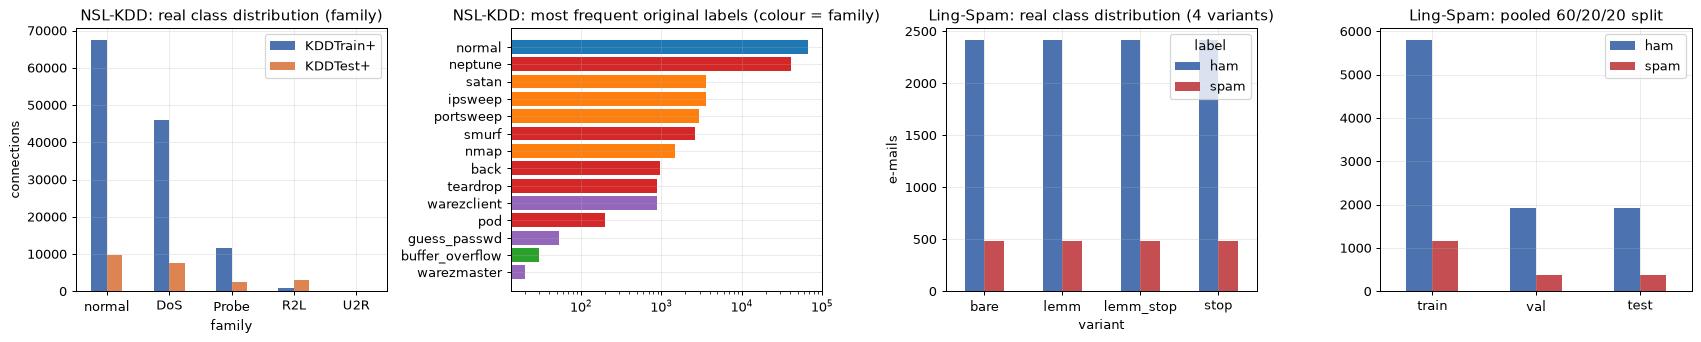

In [9]:
fam_colors = {"normal": "#1f77b4", "DoS": "#d62728", "Probe": "#ff7f0e", "R2L": "#9467bd", "U2R": "#2ca02c"}
fig, ax = plt.subplots(1, 4, figsize=(19, 3.9))
cnt = pd.DataFrame({"KDDTrain+": kdd_train["family"].value_counts(), "KDDTest+": kdd_test["family"].value_counts()}).loc[fam_order]
cnt.plot.bar(ax=ax[0], color=["#4c72b0", "#dd8452"], rot=0); ax[0].set_title("NSL-KDD: real class distribution (family)"); ax[0].set_ylabel("connections")
top = kdd_train["label"].value_counts().head(14)
ax[1].barh(top.index[::-1], top.values[::-1], color=[fam_colors[ATTACK_FAMILY[n]] for n in top.index[::-1]])
ax[1].set_xscale("log"); ax[1].set_title("NSL-KDD: most frequent original labels (colour = family)")
ls_lab = ling.assign(label=ling["y"].map({0: "ham", 1: "spam"}))
pd.crosstab(ls_lab["variant"], ls_lab["label"]).plot.bar(ax=ax[2], color=["#4c72b0", "#c44e52"], rot=0)
ax[2].set_title("Ling-Spam: real class distribution (4 variants)"); ax[2].set_ylabel("e-mails")
pd.DataFrame({p: pd.Series(ling["y"].values[ix]).map({0: "ham", 1: "spam"}).value_counts()
              for p, ix in (("train", LS["tr"]), ("val", LS["va"]), ("test", LS["te"]))}).T.plot.bar(ax=ax[3], color=["#4c72b0", "#c44e52"], rot=0)
ax[3].set_title("Ling-Spam: pooled 60/20/20 split"); plt.tight_layout(); plt.show()

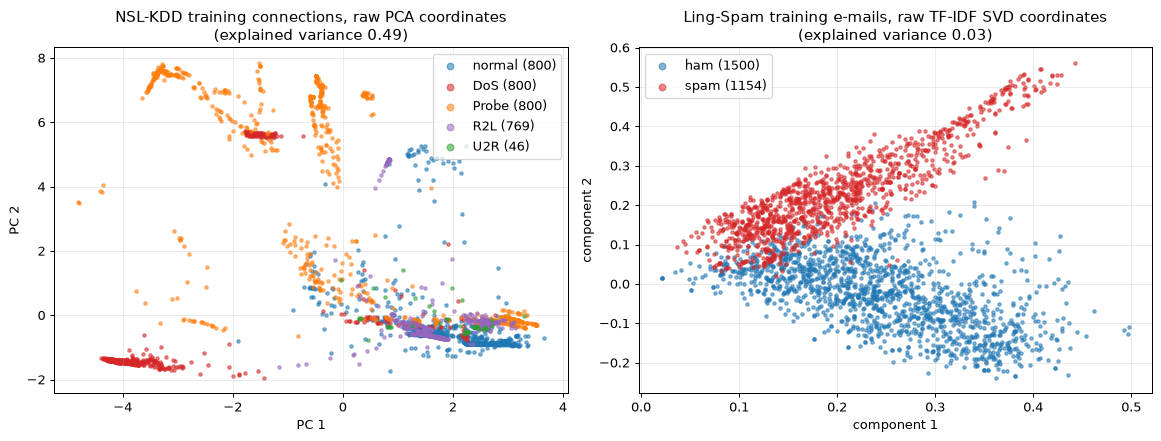

In [10]:
# 2-D scatter plots of real observations coloured by the ground-truth label.  (a) raw PCA coordinates fitted on the training partition.
rs = np.random.default_rng(SEED)
# family-stratified sample (at most 800 per family) so that the rare families R2L / U2R are visible
sub_k = np.concatenate([rs.choice(np.where(kdd_tr["family"].values == f)[0], min(800, (kdd_tr["family"].values == f).sum()), replace=False) for f in fam_order])
pca_k = PCA(n_components=2, random_state=SEED).fit(Xk_tr)
Zk = pca_k.transform(Xk_tr[sub_k]); fam_k = kdd_tr["family"].values[sub_k]
sub_l = np.concatenate([rs.choice(np.where(LS["y_tr"] == c)[0], min(1500, (LS["y_tr"] == c).sum()), replace=False) for c in (0, 1)])
svd_l = TruncatedSVD(n_components=2, random_state=SEED).fit(LS["X_tr"])        # PCA-like projection for sparse TF-IDF (fitted on train)
Zl = svd_l.transform(LS["X_tr"][sub_l]); lab_l = np.where(LS["y_tr"][sub_l] == 1, "spam", "ham")
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for f in fam_order:
    m = fam_k == f; ax[0].scatter(Zk[m, 0], Zk[m, 1], s=7, alpha=0.55, c=fam_colors[f], label=f"{f} ({m.sum()})")
ax[0].set_title(f"NSL-KDD training connections, raw PCA coordinates\n(explained variance {pca_k.explained_variance_ratio_.sum():.2f})")
ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend(markerscale=2)
for l, c in (("ham", "#1f77b4"), ("spam", "#d62728")):
    m = lab_l == l; ax[1].scatter(Zl[m, 0], Zl[m, 1], s=7, alpha=0.55, c=c, label=f"{l} ({m.sum()})")
ax[1].set_title(f"Ling-Spam training e-mails, raw TF-IDF SVD coordinates\n(explained variance {svd_l.explained_variance_ratio_.sum():.2f})")
ax[1].set_xlabel("component 1"); ax[1].set_ylabel("component 2"); ax[1].legend(markerscale=2)
plt.tight_layout(); plt.show()

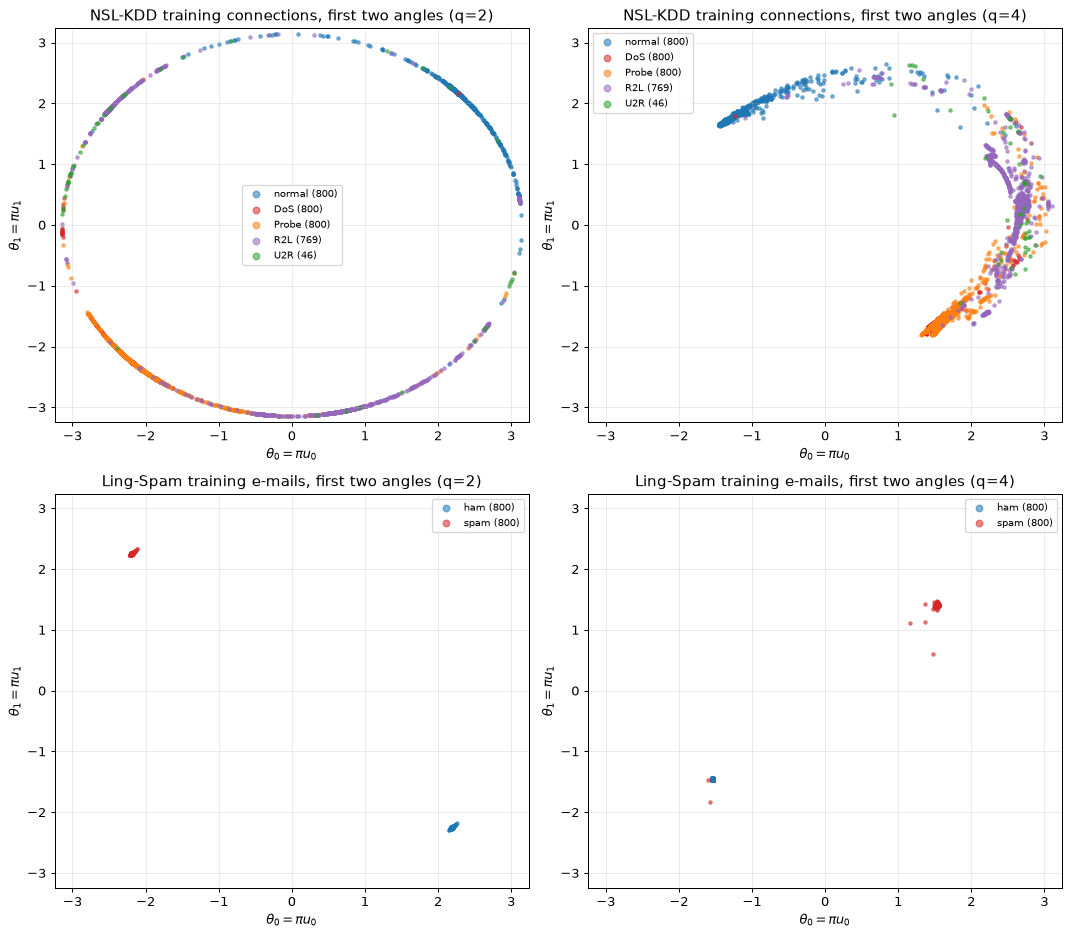

For q = 2 the pair (theta_0, theta_1) lies exactly on a circle of radius pi because ||u|| = 1: the encoder can only choose an angle on that circle.


In [11]:
# (b) the angles the quantum circuits really receive: theta_i = pi * u_i from the frozen encoder (first two coordinates).
def angle_scatter(ax, e, labels, colors, title, cap=800):
    r_ = np.random.default_rng(SEED)      # class-stratified sample (at most `cap` per label) so that rare labels are visible
    ix = np.concatenate([r_.choice(np.where(labels == l)[0], min(cap, (labels == l).sum()), replace=False) for l in colors])
    th = np.pi * e.U_tr[ix]
    for l, c in colors.items():
        m = labels[ix] == l
        ax.scatter(th[m, 0], th[m, 1], s=7, alpha=0.55, c=c, label=f"{l} ({m.sum()})")
    ax.set_xlim(-np.pi - 0.1, np.pi + 0.1); ax.set_ylim(-np.pi - 0.1, np.pi + 0.1)
    ax.set_xlabel(r"$\theta_0 = \pi u_0$"); ax.set_ylabel(r"$\theta_1 = \pi u_1$"); ax.set_title(title); ax.legend(markerscale=2, fontsize=8)
fig, ax = plt.subplots(2, 2, figsize=(12, 10.5))
for j, q in enumerate(Q_LIST):
    angle_scatter(ax[0, j], EMB[("NSL-KDD", q)], kdd_tr["family"].values, fam_colors, f"NSL-KDD training connections, first two angles (q={q})")
    angle_scatter(ax[1, j], EMB[("Ling-Spam", q)], np.where(LS["y_tr"] == 1, "spam", "ham"), {"ham": "#1f77b4", "spam": "#d62728"},
                  f"Ling-Spam training e-mails, first two angles (q={q})")
plt.tight_layout(); plt.show()
print("For q = 2 the pair (theta_0, theta_1) lies exactly on a circle of radius pi because ||u|| = 1: the encoder can only choose an angle on that circle.")

## 4. Quantum Circuit Architecture

Two gate-based quantum models are trained or evaluated, each for `q = 2` and `q = 4`, so four distinct circuits are drawn:

| Model | Circuit that is executed | Encoding | Parametrised gates | Entanglement | Measurement |
|---|---|---|---|---|---|
| **QSVM kernel** | `ZZFeatureMap(u)` followed by the inverse `ZZFeatureMap(v)^dagger` (compute-uncompute), `reps = 2` | `H` then `P(2 theta_i)` and `P(2 (pi - theta_i)(pi - theta_j))` between neighbours | none to train (the kernel is fixed; the SVM weights are classical) | linear CNOT-`P`-CNOT chain | all qubits, the bit-string `0...0` is the kernel estimate |
| **VQC** | `L = 3` re-uploading blocks | `RY(theta_i)`, `theta_i = pi u_i`, repeated in every block | `RY(w)` and `RZ(w)` per qubit and block: `2 q L` trainable angles (+ `alpha`, `beta` classical) | linear CNOT chain | `<Z>` of qubit 0 |

The paper does not give gate-level details, so the encoding gate of the VQC (`RY`), the ansatz (`RY`, `RZ`, linear CNOTs), the
number of blocks (3) and the ZZ depth (2) are our choices (`# CHOICE`). The drawings below are the circuits **as they are run**:
the QSVM pair circuit is shown after transpilation to Aer's native gate set (`rz, sx, x, cx`, no optimisation), with example
angles and the final measurement; the VQC is shown as built (its native expansion is what the simulator executes and its
counts are printed).

In [12]:
NOISE = NoiseModel(basis_gates=BASIS_GATES + ["id"])        # depolarizing noise of the paper on the physical single-qubit pulses and the CNOT
NOISE.add_all_qubit_quantum_error(depolarizing_error(P1, 1), ["sx", "x"])    # CHOICE: rz is a virtual (frame) gate and stays noiseless
NOISE.add_all_qubit_quantum_error(depolarizing_error(P2, 2), ["cx"])
AER_DM_NOISY = AerSimulator(method="density_matrix", noise_model=NOISE)
AER_DM_IDEAL = AerSimulator(method="density_matrix")

class ZZKernel:
    # compute-uncompute circuit  ZZFeatureMap(x) . ZZFeatureMap(y)^dagger  and its vectorised noisy simulator
    def __init__(self, q, reps=ZZ_REPS):
        self.q = q
        self.fx = zz_feature_map(q, reps=reps, entanglement="linear", parameter_prefix="x")
        self.fy = zz_feature_map(q, reps=reps, entanglement="linear", parameter_prefix="y")
        self.circuit = self.fx.compose(self.fy.inverse())
        self.tc = transpile(self.circuit, basis_gates=BASIS_GATES, optimization_level=0)
        self.params, self.ops = extract_gate_list(self.tc)
        assert [p.name for p in self.params] == [f"x[{i}]" for i in range(q)] + [f"y[{i}]" for i in range(q)]
        self.split = split_compute_uncompute(self.ops)
    def rho(self, A, p1=0.0, p2=0.0):                     # noisy state after the compute half, rows = samples
        return schrodinger(self.ops[:self.split], np.hstack([A, np.zeros_like(A)]), self.q, p1, p2)
    def eff(self, B, p1=0.0, p2=0.0):                     # adjoint noisy channel of the uncompute half applied to |0><0|
        return heisenberg_zero(self.ops[self.split:], np.hstack([np.zeros_like(B), B]), self.q, p1, p2)
    def prob_matrix(self, A, B, p1=0.0, p2=0.0, chunk=2048):
        E = self.eff(B, p1, p2)
        return np.vstack([all_zero_probability(self.rho(A[i:i + chunk], p1, p2), E) for i in range(0, len(A), chunk)])
    def bound_circuit(self, u, v, measure=True):
        c = self.tc.assign_parameters(dict(zip(self.params, list(u) + list(v))))
        if measure: c.measure_all()
        return c

def build_vqc(q, L):
    th, w = ParameterVector("x", q), ParameterVector("w", L * 2 * q)
    qc = QuantumCircuit(q)
    for l in range(L):
        k = l * 2 * q
        for i in range(q): qc.ry(th[i], i)                 # data (re-)uploading: theta_i = pi * u_i
        qc.barrier()
        for i in range(q): qc.ry(w[k + i], i)              # TwoLocal-style ansatz layer: RY and RZ on every qubit ...
        for i in range(q): qc.rz(w[k + q + i], i)
        for i in range(q - 1): qc.cx(i, i + 1)             # ... followed by linear nearest-neighbour CNOTs
        qc.barrier()
    return qc

class VQCEngine:
    def __init__(self, q, L=VQC_BLOCKS):
        self.q, self.L = q, L
        self.circuit = build_vqc(q, L)
        self.tc = transpile(self.circuit, basis_gates=BASIS_GATES, optimization_level=0)
        self.params, self.ops = extract_gate_list(self.tc)
        self.names = [p.name for p in self.params]
        self.n_trainable = L * 2 * q
    def P(self, theta, w):
        cols = []
        for n in self.names:
            i = int(n[2:-1]); cols.append(theta[:, i] if n[0] == "x" else np.full(len(theta), float(w[i])))
        return np.stack(cols, 1)
    def p_zero(self, theta, w, p1=0.0, p2=0.0, chunk=2048):
        # probability that qubit 0 is measured as 0 (so <Z> = 2 p - 1), for every row of theta
        d, out = 2 ** self.q, []
        for i in range(0, len(theta), chunk):
            rho = schrodinger(self.ops, self.P(theta[i:i + chunk], w), self.q, p1, p2)
            out.append(np.real(np.einsum("bii->bi", rho)[:, :d // 2].sum(1)))
        return np.concatenate(out)
    def bound_circuit(self, theta, w):
        return self.circuit.assign_parameters({p: (float(theta[int(p.name[2:-1])]) if p.name[0] == "x" else float(w[int(p.name[2:-1])])) for p in self.circuit.parameters})

ZK  = {q: ZZKernel(q) for q in Q_LIST}
VQE = {q: VQCEngine(q) for q in Q_LIST}
rows = []
for q in Q_LIST:
    for nm, eng, trainable in (("QSVM compute-uncompute", ZK[q], 0), (f"VQC (L={VQC_BLOCKS})", VQE[q], VQE[q].n_trainable)):
        rows.append(dict(model=nm, qubits=q, depth_native=eng.tc.depth(), native_gates=dict(eng.tc.count_ops()),
                         input_parameters=(2 * q if "QSVM" in nm else q), trainable_parameters=trainable))
display(pd.DataFrame(rows))

,model,qubits,depth_native,native_gates,input_parameters,trainable_parameters
0,QSVM compute-uncompute,2,28,"{'rz': 28, 'sx': 8, 'cx': 8}",4,0
1,VQC (L=3),2,36,"{'rz': 42, 'sx': 24, 'barrier': 6, 'cx': 3}",2,12
2,QSVM compute-uncompute,4,46,"{'rz': 60, 'cx': 24, 'sx': 16}",8,0
3,VQC (L=3),4,42,"{'rz': 84, 'sx': 48, 'cx': 9, 'barrier': 6}",4,24


QSVM kernel circuit, q=2: 2 qubits, depth 29 (native gates), 46 operations, 0 trainable parameters, 4 input angles (u for the compute half, v for the uncompute half)


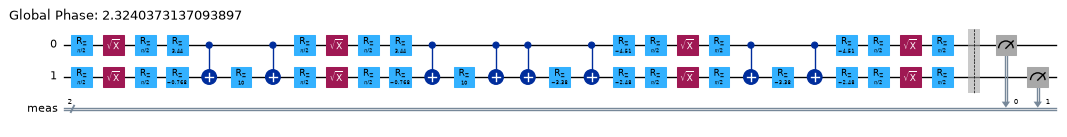

QSVM kernel circuit, q=4: 4 qubits, depth 47 (native gates), 104 operations, 0 trainable parameters, 8 input angles (u for the compute half, v for the uncompute half)


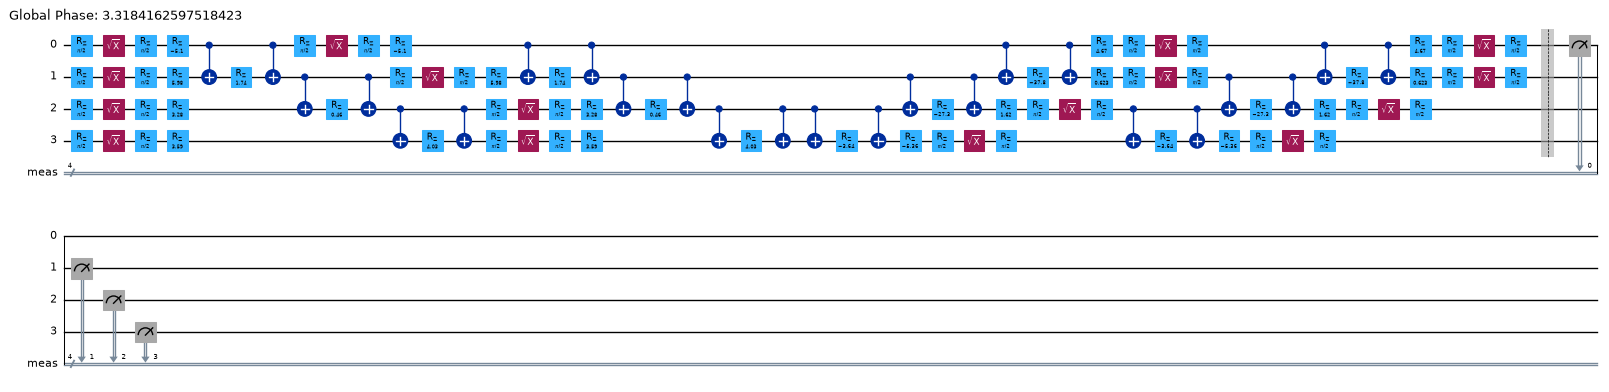

In [13]:
rs = np.random.default_rng(SEED)
for q in Q_LIST:
    u, v = rs.uniform(-np.pi, np.pi, q), rs.uniform(-np.pi, np.pi, q)
    c = ZK[q].bound_circuit(u, v)
    print(f"QSVM kernel circuit, q={q}: {c.num_qubits} qubits, depth {c.depth()} (native gates), {c.size()} operations, "
          f"0 trainable parameters, {2*q} input angles (u for the compute half, v for the uncompute half)")
    display(c.draw("mpl", fold=48, scale=0.55))

VQC, q=2, L=3: 2 qubits, logical depth 12, native depth 36, 12 trainable circuit parameters (+2 classical: alpha, beta), 2 input angles per block (re-uploaded 3x)


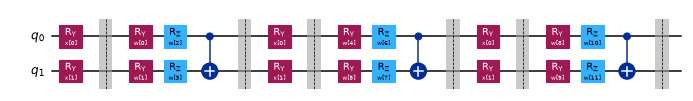

VQC, q=4, L=3: 4 qubits, logical depth 18, native depth 42, 24 trainable circuit parameters (+2 classical: alpha, beta), 4 input angles per block (re-uploaded 3x)


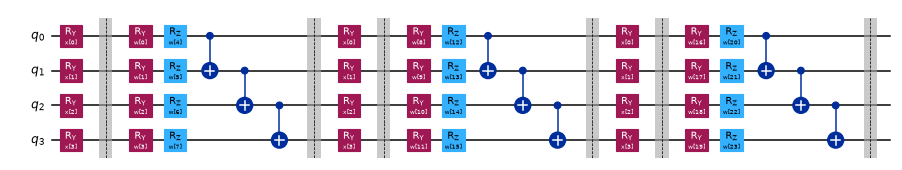

In [14]:
for q in Q_LIST:
    eng = VQE[q]
    w0 = rs.uniform(0, 2 * np.pi, eng.n_trainable)
    print(f"VQC, q={q}, L={VQC_BLOCKS}: {eng.circuit.num_qubits} qubits, logical depth {eng.circuit.decompose().depth()}, native depth {eng.tc.depth()}, "
          f"{eng.n_trainable} trainable circuit parameters (+2 classical: alpha, beta), {q} input angles per block (re-uploaded {VQC_BLOCKS}x)")
    display(eng.circuit.draw("mpl", fold=60, scale=0.6))

### Equivalence checks: the fast simulator is the real circuit

Four assertions tie the vectorised simulator (used for the thousands of kernel entries) to Qiskit / Aer:

1. **Noiseless QSVM kernel** equals `|<phi(u)|phi(v)>|^2` computed with `qiskit.quantum_info.Statevector`.
2. **Noisy QSVM kernel** equals the all-zero probability of Aer's density-matrix simulation of the same transpiled circuit with
   the depolarizing noise model.
3. **Shot-based Aer runs** (1,024 shots, trajectory sampling of the real noisy circuit) agree with the simulator's probability
   within binomial statistics (|z| < 4).
4. **VQC**: the PyTorch statevector used for training and the noisy density-matrix evaluator both match Qiskit (`Statevector`
   and Aer) for `<Z>`.

In [15]:
def ry_t(a):
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
def rz_t(a):
    e = torch.exp(-0.5j * a); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)
def apply1(psi, G, k):
    x = torch.movedim(psi, 1 + k, -1); G = G.to(psi.dtype)
    y = torch.einsum("bij,b...j->b...i", G, x) if G.dim() == 3 else torch.einsum("ij,b...j->b...i", G, x)
    return torch.movedim(y, -1, 1 + k)

class TorchVQC(nn.Module):
    # exact statevector simulation of the VQC circuit above (same gate order), differentiable with autograd
    def __init__(self, q, L=VQC_BLOCKS):
        super().__init__()
        self.q, self.L = q, L
        self.w = nn.Parameter(torch.rand(L, 2, q, dtype=torch.float64) * 2 * math.pi)       # CHOICE: uniform [0, 2 pi) initial angles
        self.alpha = nn.Parameter(torch.tensor(2.0, dtype=torch.float64))                     # sigmoid(alpha z + beta)
        self.beta = nn.Parameter(torch.zeros((), dtype=torch.float64))
        self.cx_perm = [torch.from_numpy(_perm_cx(q, i, i + 1)) for i in range(q - 1)]
    def zexp(self, theta):
        B, q = theta.shape[0], self.q
        psi = torch.zeros((B,) + (2,) * q, dtype=torch.complex128); psi.view(B, -1)[:, 0] = 1
        for l in range(self.L):
            for i in range(q): psi = apply1(psi, ry_t(theta[:, i]), i)
            for i in range(q): psi = apply1(psi, ry_t(self.w[l, 0, i]), i)
            for i in range(q): psi = apply1(psi, rz_t(self.w[l, 1, i]), i)
            for p in self.cx_perm: psi = psi.reshape(B, -1)[:, p].reshape(psi.shape)
        pr = (psi.abs() ** 2).reshape(B, 2, -1).sum(-1)              # qubit 0 is the first tensor axis
        return pr[:, 0] - pr[:, 1]
    def logit(self, z):
        return self.alpha * z + self.beta

rs = np.random.default_rng(SEED + 1)
check = []
for q in Q_LIST:
    zk = ZK[q]
    # (1) + (2) QSVM kernel
    U, V = rs.uniform(-np.pi, np.pi, (6, q)), rs.uniform(-np.pi, np.pi, (6, q))
    P0 = zk.prob_matrix(U, V)                                                       # noiseless
    Pn = zk.prob_matrix(U, V, P1, P2)                                               # noisy
    sv = lambda z: Statevector(zk.fx.assign_parameters(z))
    ex = np.array([[abs(sv(U[i]).inner(sv(V[j]))) ** 2 for j in range(6)] for i in range(6)])
    e1 = np.abs(ex - P0).max()
    e2 = 0.0
    for i, j in [(0, 1), (2, 2), (3, 5), (4, 0)]:
        c = zk.bound_circuit(U[i], V[j], measure=False); c.save_probabilities(list(range(q)))
        e2 = max(e2, abs(AER_DM_NOISY.run(c).result().data()["probabilities"][0] - Pn[i, j]))
    # (3) shot-based Aer trajectories of the real noisy circuit
    zs = []
    for k, (i, j) in enumerate([(0, 1), (2, 2), (3, 5), (4, 0), (1, 3)]):
        c = zk.bound_circuit(U[i], V[j])
        cnt = AerSimulator(noise_model=NOISE).run(c, shots=SHOTS, seed_simulator=SEED + k).result().get_counts()
        ph = cnt.get("0" * q, 0) / SHOTS
        zs.append((ph - Pn[i, j]) / math.sqrt(max(Pn[i, j] * (1 - Pn[i, j]), 1e-9) / SHOTS))
    # (4) VQC
    ve = VQE[q]
    th, wf = rs.uniform(-np.pi, np.pi, (5, q)), rs.uniform(0, 2 * np.pi, ve.n_trainable)
    mdl = TorchVQC(q); mdl.w.data = torch.from_numpy(wf.reshape(VQC_BLOCKS, 2, q))
    z_t = mdl.zexp(torch.from_numpy(th)).detach().numpy()
    z_q = np.array([2 * Statevector(ve.bound_circuit(th[i], wf)).probabilities([0])[0] - 1 for i in range(5)])
    z_n = 2 * ve.p_zero(th, wf) - 1
    pn = ve.p_zero(th, wf, P1, P2); e4 = 0.0
    for i in range(5):
        c = ve.tc.assign_parameters({p: (th[i][int(p.name[2:-1])] if p.name[0] == "x" else wf[int(p.name[2:-1])]) for p in ve.tc.parameters})
        c.save_probabilities([0])
        e4 = max(e4, abs(AER_DM_NOISY.run(c).result().data()["probabilities"][0] - pn[i]))
    check.append(dict(q=q, kernel_vs_Statevector=e1, kernel_noisy_vs_Aer=e2, shot_z_max=float(np.abs(zs).max()),
                      vqc_torch_vs_Statevector=float(np.abs(z_t - z_q).max()), vqc_numpy_vs_Statevector=float(np.abs(z_n - z_q).max()), vqc_noisy_vs_Aer=e4))
    assert e1 < 1e-9 and e2 < 1e-9 and np.abs(zs).max() < 4 and np.abs(z_t - z_q).max() < 1e-9 and np.abs(z_n - z_q).max() < 1e-9 and e4 < 1e-9
display(pd.DataFrame(check).style.format({c: "{:.2e}" for c in ["kernel_vs_Statevector", "kernel_noisy_vs_Aer", "vqc_torch_vs_Statevector", "vqc_numpy_vs_Statevector", "vqc_noisy_vs_Aer"]} | {"shot_z_max": "{:.2f}"}))
print("all equivalence assertions passed: the vectorised simulators reproduce the real Qiskit / Aer circuits")
for q in Q_LIST:
    A = rs.uniform(-np.pi, np.pi, (50, q))
    print(f"q={q}: mean noisy self-overlap k(u,u) = {np.diag(ZK[q].prob_matrix(A, A, P1, P2)).mean():.3f}  (ideal value 1; the gap is the depolarizing noise of the paper)")

,q,kernel_vs_Statevector,kernel_noisy_vs_Aer,shot_z_max,vqc_torch_vs_Statevector,vqc_numpy_vs_Statevector,vqc_noisy_vs_Aer
0,2,2.12e-14,1.47e-14,2.50,9.99e-16,6.44e-15,2.33e-15
1,4,1.77e-14,1.55e-15,2.25,6.66e-16,1.23e-14,6.55e-15


all equivalence assertions passed: the vectorised simulators reproduce the real Qiskit / Aer circuits
q=2: mean noisy self-overlap k(u,u) = 0.938  (ideal value 1; the gap is the depolarizing noise of the paper)
q=4: mean noisy self-overlap k(u,u) = 0.819  (ideal value 1; the gap is the depolarizing noise of the paper)


## 5. Metrics, operating point and the classical heads

**Metrics** (as in the paper): accuracy, macro-F1 (mean of the two class F1 scores), AUROC and AUPRC with attack / spam as the
positive class. **Operating point:** for *every* head the decision threshold is the value on the validation scores that maximises
validation macro-F1, then frozen for the test set (the paper selects "operating threshold on the validation split").
AUROC / AUPRC use the raw scores and need no threshold.

**Classical heads on identical inputs.** All heads see the same frozen `u` (q numbers per sample):

| Head | Trained on | Role |
|---|---|---|
| `MLP+Linear` | full training partition, jointly with the encoder | the paper's matched classical baseline |
| `MLP+SVC(RBF)` | the same reference set as the QSVM | classical *kernel* counterpart of the QSVM |
| `MLP+RF` | the same reference set | non-parametric reference |
| `MLP+tiny MLP` | the same samples as the VQC | **parameter-matched** to the VQC (same number of trainable weights) |
| `RF (all features)` | up to 20,000 training rows, *no* encoder | what the 2-4 number bottleneck costs |

In [16]:
def macro_f1(y, p):
    y, p = np.asarray(y), np.asarray(p)
    tp, fp, fn, tn = ((p == 1) & (y == 1)).sum(), ((p == 1) & (y == 0)).sum(), ((p == 0) & (y == 1)).sum(), ((p == 0) & (y == 0)).sum()
    f1p = 2 * tp / max(2 * tp + fp + fn, 1); f1n = 2 * tn / max(2 * tn + fn + fp, 1)
    return (f1p + f1n) / 2

def best_threshold(s, y):
    cand = np.unique(np.quantile(s, np.linspace(0.005, 0.995, 199)))
    return float(cand[int(np.argmax([macro_f1(y, (s >= t).astype(int)) for t in cand]))])

def metrics(s, y, thr):
    y = np.asarray(y); p = (s >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(acc=accuracy_score(y, p), f1_macro=macro_f1(y, p), f1_pos=f1_score(y, p, zero_division=0),
                auroc=roc_auc_score(y, s), auprc=average_precision_score(y, s), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), thr=float(thr))

def make_split(emb, seed):
    rng = np.random.default_rng(seed)
    return dict(ref=stratified_subset(emb.y_tr, N_REF, rng), val=stratified_subset(emb.y_va, N_VAL, rng),
                vqc=stratified_subset(emb.y_tr, VQC_TRAIN, rng))

def pick_on_validation(make_scores, grid, y_val):
    # fit one model per hyper-parameter value, keep the one with the best validation macro-F1 at its own best threshold
    best = None
    for g in grid:
        sv, st, extra = make_scores(g)
        thr = best_threshold(sv, y_val); f = macro_f1(y_val, (sv >= thr).astype(int))
        if best is None or f > best[0]: best = (f, g, sv, st, thr, extra)
    return best

def head_linear(emb, sp):
    return emb.lin_va[sp["val"]], emb.lin_te

def head_rbf(emb, sp, seed):
    ref = sp["ref"]; yv = emb.y_va[sp["val"]]
    def mk(gc):
        C_, gam = gc
        m = SVC(kernel="rbf", C=C_, gamma=gam, class_weight="balanced").fit(emb.U_tr[ref], emb.y_tr[ref])
        return m.decision_function(emb.U_va[sp["val"]]), m.decision_function(emb.U_te), None
    b = pick_on_validation(mk, [(c, g) for c in C_GRID for g in (0.5, 1, 2, 4, 8, 16)], yv)
    return b[2], b[3]

def head_rf(emb, sp, seed):
    ref = sp["ref"]
    m = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=seed, n_jobs=1).fit(emb.U_tr[ref], emb.y_tr[ref])
    return m.predict_proba(emb.U_va[sp["val"]])[:, 1], m.predict_proba(emb.U_te)[:, 1]

def tiny_mlp_hidden(q):                      # hidden units so that the tiny MLP has about as many weights as the VQC (2 q L + 2)
    return max(2, int(round((VQC_BLOCKS * 2 * q + 2 - 1) / (q + 2))))

def head_tiny_mlp(emb, sp, seed):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    h = tiny_mlp_hidden(emb.q)
    net = nn.Sequential(nn.Linear(emb.q, h), nn.Tanh(), nn.Linear(h, 1))
    n_par = sum(p.numel() for p in net.parameters())
    X = torch.from_numpy(emb.U_tr[sp["vqc"]]).float(); y = torch.from_numpy(emb.y_tr[sp["vqc"]]).float()
    Xv = torch.from_numpy(emb.U_va[sp["val"]]).float(); yv = torch.from_numpy(emb.y_va[sp["val"]]).float()
    cw = torch.from_numpy(class_weights(emb.y_tr[sp["vqc"]]))
    opt = torch.optim.Adam(net.parameters(), lr=0.02)
    best, state, bad = 1e9, None, 0
    for ep in range(VQC_EPOCHS):
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), 256):
            b = perm[i:i + 256]; opt.zero_grad(); wbce(net(X[b]).squeeze(1), y[b], cw).backward(); opt.step()
        with torch.no_grad(): vl = wbce(net(Xv).squeeze(1), yv, cw).item()
        if vl < best - 1e-5: best, bad, state = vl, 0, {k: v.clone() for k, v in net.state_dict().items()}
        else:
            bad += 1
            if bad >= VQC_PATIENCE: break
    net.load_state_dict(state)
    with torch.no_grad():
        return net(Xv).squeeze(1).numpy(), net(torch.from_numpy(emb.U_te).float()).squeeze(1).numpy(), n_par

def head_rf_all(name, seed):
    if name == "NSL-KDD":
        Xt, yt, Xv, yv, Xe, ye = Xk_tr, yk_tr, Xk_va, yk_va, Xk_te_full[kdd_eval_idx], yk_te_full[kdd_eval_idx]
    else:
        Xt, yt, Xv, yv, Xe, ye = LS["X_tr"], LS["y_tr"], LS["X_va"], LS["y_va"], LS["X_te"], LS["y_te"]
    ix = stratified_subset(yt, 20000, np.random.default_rng(seed))
    m = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=seed, n_jobs=1).fit(Xt[ix], yt[ix])
    return m.predict_proba(Xv)[:, 1], yv, m.predict_proba(Xe)[:, 1]
print("classical heads defined; tiny-MLP hidden units:", {q: tiny_mlp_hidden(q) for q in Q_LIST},
      "| VQC trainable weights:", {q: VQC_BLOCKS * 2 * q + 2 for q in Q_LIST})

classical heads defined; tiny-MLP hidden units: {2: 3, 4: 4} | VQC trainable weights: {2: 14, 4: 26}


## 6. Quantum head A: the QSVM with a noisy, shot-based, double-centred kernel

For the **reference set** `R` (a stratified random sample of the training partition) the Gram matrix `K_ij = p_hat(0^q)` of the
compute-uncompute circuit is estimated with 1,024 shots under the depolarizing noise (1e-3 / 1e-2), exactly as the paper
describes (the upper triangle is measured once and mirrored; the diagonal is *measured*, so it is below 1 because of noise).
The Gram matrix is **double-centred** with training statistics, validation and test rows are centred out-of-sample with the same
statistics, and a classical `SVC(kernel="precomputed", class_weight="balanced")` is fitted. `C` and the decision threshold are
chosen on the validation rows. The only quantum work at prediction time is the kernel row `k(u, R)` (`|R|` circuits per sample).

demo QSVM (Ling-Spam, q=4): |R| = 1000, mean measured k(u,u) = 0.818, smallest eigenvalue of the centred Gram matrix = -8.03e-01, chosen C = 0.1, validation macro-F1 = 0.9982   (4.4s)


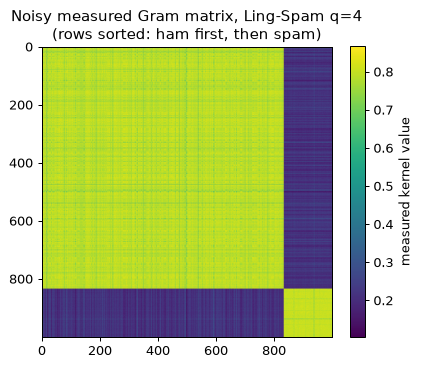

In [17]:
def sample_shots(P, rng, shots):
    return P if shots is None else rng.binomial(shots, np.clip(P, 0, 1)) / shots      # all-zero count of a shot-based run ~ Binomial(shots, p)

def center_train(K):
    cm = K.mean(0); mm = K.mean()
    return K - cm[None, :] - cm[:, None] + mm, cm, mm                                    # double centring of the training Gram matrix
def center_rows(Kr, cm, mm):
    return Kr - Kr.mean(1, keepdims=True) - cm[None, :] + mm                             # out-of-sample centring with training statistics

RHO_CACHE = {}

class QSVMModel:
    # a fitted (frozen) QSVM: reference set, noisy sampled Gram matrix, centring statistics, SVC and threshold
    def __init__(self, emb, seed, noisy=True, shots=SHOTS, split=None, n_ref=None):
        self.emb, self.noisy, self.shots = emb, noisy, shots
        self.q, self.zk = emb.q, ZK[emb.q]
        self.p1, self.p2 = (P1, P2) if noisy else (0.0, 0.0)
        self.rng = np.random.default_rng(1000 + seed)
        sp = split or make_split(emb, seed)
        if n_ref is not None: sp = dict(sp, ref=stratified_subset(emb.y_tr, n_ref, np.random.default_rng(seed)))
        self.sp, ref = sp, sp["ref"]
        self.A, self.yref = np.pi * emb.U_tr[ref], emb.y_tr[ref]
        P = self.zk.prob_matrix(self.A, self.A, self.p1, self.p2)
        Ks = sample_shots(P, self.rng, shots); K = np.triu(Ks) + np.triu(Ks, 1).T
        self.K = K; self.Kc, self.cm, self.mm = center_train(K)
        self.min_eig = float(np.linalg.eigvalsh(self.Kc).min()); self.diag_mean = float(np.diag(K).mean())
        self.E = self.zk.eff(self.A, self.p1, self.p2)
        yv = emb.y_va[sp["val"]]
        Kv = self.rows(emb.U_va[sp["val"]])
        def mk(Cc):
            svc = SVC(kernel="precomputed", C=Cc, class_weight="balanced").fit(self.Kc, self.yref)
            return svc.decision_function(Kv), None, svc
        f, self.C, self.s_val, _, self.thr, self.svc = pick_on_validation(mk, C_GRID, yv)
        self.val_f1 = f
    def _rho_chunks(self, U, chunk, key):
        # noisy compute-half states are data-only (independent of the reference set), so rows that are identical in every repeat are cached
        ck = (self.q, self.p1, self.p2, key)
        if key is not None and ck in RHO_CACHE: return RHO_CACHE[ck]
        ch = [self.zk.rho(np.pi * U[i:i + chunk], self.p1, self.p2) for i in range(0, len(U), chunk)]
        if key is not None: RHO_CACHE[ck] = ch
        return ch
    def rows(self, U, chunk=2048, key=None):
        out = []
        for rho in self._rho_chunks(U, chunk, key):
            P = all_zero_probability(rho, self.E)
            out.append(center_rows(sample_shots(P, self.rng, self.shots), self.cm, self.mm))
        return np.vstack(out)
    def score(self, U, chunk=2048, key=None):        # decision values for new embeddings (kernel rows are measured fresh)
        return np.concatenate([self.svc.decision_function(K) for K in self._chunked_rows(U, chunk, key)])
    def _chunked_rows(self, U, chunk, key):
        for rho in self._rho_chunks(U, chunk, key):
            P = all_zero_probability(rho, self.E)
            yield center_rows(sample_shots(P, self.rng, self.shots), self.cm, self.mm)

t0 = time.time()
demo = QSVMModel(EMB[("Ling-Spam", 4)], SEED)
print(f"demo QSVM (Ling-Spam, q=4): |R| = {len(demo.A)}, mean measured k(u,u) = {demo.diag_mean:.3f}, smallest eigenvalue of the centred Gram matrix = {demo.min_eig:.2e}, "
      f"chosen C = {demo.C}, validation macro-F1 = {demo.val_f1:.4f}   ({time.time()-t0:.1f}s)")
plt.figure(figsize=(5.2, 4.2)); plt.imshow(demo.K[np.argsort(demo.yref)][:, np.argsort(demo.yref)], cmap="viridis")
plt.colorbar(label="measured kernel value"); plt.title("Noisy measured Gram matrix, Ling-Spam q=4\n(rows sorted: ham first, then spam)"); plt.grid(False); plt.show()

## 7. Quantum head B: the data re-uploading VQC

`L = 3` blocks of `RY(pi u_i)` encoding followed by a TwoLocal-style layer (`RY`, `RZ`, linear CNOTs); the logit is
`alpha * <Z_0> + beta`. Training uses a PyTorch statevector simulation that was asserted equal to Qiskit above, exact
gradients, Adam, balanced class weights, Gaussian **shot noise on `<Z>`** (variance `(1 - z^2)/1024`, which is what 1,024 shots
produce) and early stopping on the validation loss. Evaluation then uses the **noisy shot-based simulator** (depolarizing
noise + Binomial shots) on the validation and test rows, just like the QSVM.

demo VQC (Ling-Spam, q=2): 100 epochs, best validation loss 0.0003, alpha = 8.12, beta = 0.00 (28.1s)


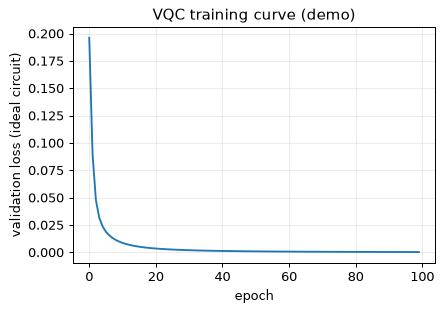

In [18]:
class VQCModel:
    def __init__(self, emb, seed, split=None):
        self.emb, self.q, self.eng = emb, emb.q, VQE[emb.q]
        self.rng = np.random.default_rng(2000 + seed)
        sp = split or make_split(emb, seed); self.sp = sp
        torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
        self.model = TorchVQC(self.q)
        th = torch.from_numpy(np.pi * emb.U_tr[sp["vqc"]]); y = torch.from_numpy(emb.y_tr[sp["vqc"]].astype(np.float64))
        thv = torch.from_numpy(np.pi * emb.U_va[sp["val"]]); yv = torch.from_numpy(emb.y_va[sp["val"]].astype(np.float64))
        cw = torch.from_numpy(class_weights(emb.y_tr[sp["vqc"]])).double()
        opt = torch.optim.Adam(self.model.parameters(), lr=VQC_LR)
        best, state, bad, self.hist = 1e9, None, 0, []
        for ep in range(VQC_EPOCHS):
            perm = torch.randperm(len(th), generator=g)
            for i in range(0, len(th), 256):
                b = perm[i:i + 256]
                z = self.model.zexp(th[b])
                z = z + torch.sqrt(torch.clamp((1 - z ** 2) / SHOTS, min=0)).detach() * torch.randn(z.shape, generator=g, dtype=torch.float64)   # shot noise
                opt.zero_grad(); wbce(self.model.logit(z), y[b], cw).backward(); opt.step()
            with torch.no_grad(): vl = wbce(self.model.logit(self.model.zexp(thv)), yv, cw).item()
            self.hist.append(vl)
            if vl < best - 1e-5: best, bad, state = vl, 0, {k: v.clone() for k, v in self.model.state_dict().items()}
            else:
                bad += 1
                if bad >= VQC_PATIENCE: break
        self.model.load_state_dict(state); self.best_val_loss = best
        self.w = self.model.w.detach().numpy().reshape(-1)
        self.alpha, self.beta = float(self.model.alpha), float(self.model.beta)
    def score(self, U, noisy=True):
        if not noisy:                                  # ideal circuit: the PyTorch statevector (asserted equal to Qiskit above)
            with torch.no_grad(): z = self.model.zexp(torch.from_numpy(np.pi * U)).numpy()
            return self.alpha * z + self.beta
        p0 = self.eng.p_zero(np.pi * U, self.w, P1, P2)
        z = 2 * self.rng.binomial(SHOTS, np.clip(p0, 0, 1)) / SHOTS - 1
        return self.alpha * z + self.beta

t0 = time.time()
vd = VQCModel(EMB[("Ling-Spam", 2)], SEED)
print(f"demo VQC (Ling-Spam, q=2): {len(vd.hist)} epochs, best validation loss {vd.best_val_loss:.4f}, alpha = {vd.alpha:.2f}, beta = {vd.beta:.2f} ({time.time()-t0:.1f}s)")
plt.figure(figsize=(5.2, 3.4)); plt.plot(vd.hist); plt.xlabel("epoch"); plt.ylabel("validation loss (ideal circuit)"); plt.title("VQC training curve (demo)"); plt.show()

## 8. Run every head on both datasets (Tables I and II)

For each dataset and each `q`, every head is run `N_REPEATS` times (seeds `SEED, SEED+1, ...`). A repeat re-draws the reference
set, the validation rows, the VQC training rows, the shot noise and the VQC initial angles; **the frozen encoder is shared**, as
in the paper's attribution-safe design. The first repeat (seed 42) is the "main" run shown in the comparison tables.

In [19]:
HEADS = ["MLP+Linear", "MLP+QSVM", "MLP+QSVM (ideal)", "MLP+VQC", "MLP+VQC (ideal)", "MLP+SVC(RBF)", "MLP+RF", "MLP+tiny MLP"]
RUNS = {}        # RUNS[(dataset, q)][head] = list over repeats of metric dicts (+ test scores)
MODELS = {}      # frozen main-run models, reused for hardware proxy / robustness / near-boundary analysis
t_all = time.time()
for (ds, q), emb in EMB.items():
    RUNS[(ds, q)] = {h: [] for h in HEADS}
    for r in range(N_REPEATS):
        seed = SEED + r; t0 = time.time()
        sp = make_split(emb, seed); yv, yt = emb.y_va[sp["val"]], emb.y_te
        def add(name, sv, st, **kw):
            thr = best_threshold(sv, yv); m = metrics(st, yt, thr); m.update(kw); m["scores"] = st; RUNS[(ds, q)][name].append(m)
        add("MLP+Linear", *head_linear(emb, sp))
        qs = QSVMModel(emb, seed, split=sp); add("MLP+QSVM", qs.s_val, qs.score(emb.U_te, key=(ds, "test")), C=qs.C, min_eig=qs.min_eig, diag=qs.diag_mean)
        qi = QSVMModel(emb, seed, noisy=False, shots=None, split=sp); add("MLP+QSVM (ideal)", qi.s_val, qi.score(emb.U_te, key=(ds, "test")), C=qi.C)
        vq = VQCModel(emb, seed, split=sp)
        add("MLP+VQC", vq.score(emb.U_va[sp["val"]]), vq.score(emb.U_te), epochs=len(vq.hist))
        add("MLP+VQC (ideal)", vq.score(emb.U_va[sp["val"]], noisy=False), vq.score(emb.U_te, noisy=False))
        add("MLP+SVC(RBF)", *head_rbf(emb, sp, seed))
        add("MLP+RF", *head_rf(emb, sp, seed))
        sv, st, n_par = head_tiny_mlp(emb, sp, seed); add("MLP+tiny MLP", sv, st, n_params=n_par)
        if r == 0: MODELS[(ds, q)] = dict(qsvm=qs, vqc=vq, split=sp)
        a = RUNS[(ds, q)]
        print(f"{ds:9s} q={q} repeat {r}: linear {a['MLP+Linear'][-1]['acc']:.4f} | QSVM {a['MLP+QSVM'][-1]['acc']:.4f} | VQC {a['MLP+VQC'][-1]['acc']:.4f}  (accuracy)   [{time.time()-t0:.0f}s]")
print(f"all heads done in {(time.time()-t_all)/60:.1f} min")

NSL-KDD   q=2 repeat 0: linear 0.7834 | QSVM 0.7657 | VQC 0.7994  (accuracy)   [44s]


NSL-KDD   q=2 repeat 1: linear 0.7812 | QSVM 0.7497 | VQC 0.7600  (accuracy)   [32s]


NSL-KDD   q=2 repeat 2: linear 0.7770 | QSVM 0.7599 | VQC 0.8054  (accuracy)   [29s]


NSL-KDD   q=2 repeat 3: linear 0.7709 | QSVM 0.7846 | VQC 0.7790  (accuracy)   [25s]


NSL-KDD   q=2 repeat 4: linear 0.7706 | QSVM 0.7682 | VQC 0.7991  (accuracy)   [25s]


...

Ling-Spam q=4 repeat 0: linear 0.9991 | QSVM 0.9991 | VQC 0.9991  (accuracy)   [46s]


Ling-Spam q=4 repeat 1: linear 0.9991 | QSVM 0.9991 | VQC 0.9991  (accuracy)   [23s]


Ling-Spam q=4 repeat 2: linear 0.9987 | QSVM 0.9987 | VQC 0.9983  (accuracy)   [34s]


Ling-Spam q=4 repeat 3: linear 0.9987 | QSVM 0.9987 | VQC 0.9974  (accuracy)   [50s]


Ling-Spam q=4 repeat 4: linear 0.9991 | QSVM 0.9991 | VQC 0.9991  (accuracy)   [48s]
all heads done in 16.9 min


In [20]:
PAPER_T1 = {"MLP+Linear": (0.6911, 0.6613, 0.7411, 0.7032), ("MLP+QSVM", 2): (0.8410, 0.8322, 0.8802, 0.9057), ("MLP+QSVM", 4): (0.9212, 0.9098, 0.9335, 0.9407),
            ("MLP+VQC", 2): (0.8522, 0.8410, 0.8899, 0.9289), ("MLP+VQC", 4): (0.8073, 0.7907, 0.9365, 0.9402)}
PAPER_T2 = {"MLP+Linear": (0.9214, 0.9001, 0.9504, 0.9103), ("MLP+QSVM", 2): (0.9883, 0.9710, 0.9990, 0.9768), ("MLP+QSVM", 4): (0.9996, 0.9987, 1.0000, 1.0000),
            ("MLP+VQC", 2): (0.9810, 0.9788, 0.9997, 0.9894), ("MLP+VQC", 4): (0.9857, 0.9552, 0.9995, 0.9985)}
PAPER = {"NSL-KDD": PAPER_T1, "Ling-Spam": PAPER_T2}
MET = ["acc", "f1_macro", "auroc", "auprc"]; MET_NAMES = ["Acc", "F1 macro", "AUROC", "AUPRC"]

def table_for(ds, heads=HEADS):
    rows = []
    for q in Q_LIST:
        for h in heads:
            runs = RUNS[(ds, q)][h]
            if not runs: continue
            r0 = runs[0]
            row = {"Model": f"{h} (q={q})", "seed 42: " + MET_NAMES[0]: r0["acc"]}
            for m, n in zip(MET[1:], MET_NAMES[1:]): row["seed 42: " + n] = r0[m]
            for m, n in zip(MET, MET_NAMES):
                v = np.array([x[m] for x in runs]); row[f"mean +- std: {n}"] = f"{v.mean():.4f} +- {v.std():.4f}"
            rows.append(row)
    return pd.DataFrame(rows).set_index("Model")

for ds, tag in (("NSL-KDD", "Table I"), ("Ling-Spam", "Table II")):
    print(f"==== {tag}: {ds} under shot-based noisy simulation (notebook; evaluation rows = {len(EMB[(ds, 4)].y_te):,}; {N_REPEATS} repeats) ====")
    display(table_for(ds).style.format({c: "{:.4f}" for c in [f"seed 42: {n}" for n in MET_NAMES]}))

==== Table I: NSL-KDD under shot-based noisy simulation (notebook; evaluation rows = 22,544; 5 repeats) ====


,seed 42: Acc,seed 42: F1 macro,seed 42: AUROC,seed 42: AUPRC,mean +- std: Acc,mean +- std: F1 macro,mean +- std: AUROC,mean +- std: AUPRC
Model,,,,,,,,
MLP+Linear (q=2),0.7834,0.7833,0.9399,0.9498,0.7766 +- 0.0052,0.7764 +- 0.0053,0.9399 +- 0.0000,0.9498 +- 0.0000
MLP+QSVM (q=2),0.7657,0.7653,0.8140,0.8559,0.7656 +- 0.0114,0.7650 +- 0.0119,0.7915 +- 0.0147,0.8554 +- 0.0024
MLP+QSVM (ideal) (q=2),0.7729,0.7726,0.6938,0.7872,0.7763 +- 0.0067,0.7761 +- 0.0068,0.7088 +- 0.0241,0.8090 +- 0.0179
MLP+VQC (q=2),0.7994,0.7994,0.9412,0.9503,0.7886 +- 0.0169,0.7884 +- 0.0171,0.9279 +- 0.0115,0.9435 +- 0.0061
MLP+VQC (ideal) (q=2),0.8023,0.8023,0.9434,0.9516,0.8036 +- 0.0086,0.8036 +- 0.0085,0.9321 +- 0.0114,0.9462 +- 0.0053
MLP+SVC(RBF) (q=2),0.7836,0.7835,0.9306,0.9182,0.7780 +- 0.0045,0.7778 +- 0.0046,0.9123 +- 0.0201,0.9150 +- 0.0152
MLP+RF (q=2),0.7824,0.7823,0.8775,0.8913,0.7793 +- 0.0066,0.7792 +- 0.0067,0.8649 +- 0.0077,0.8805 +- 0.0067
MLP+tiny MLP (q=2),0.7836,0.7835,0.9352,0.9481,0.7765 +- 0.0056,0.7763 +- 0.0057,0.9122 +- 0.0235,0.9378 +- 0.0098
MLP+Linear (q=4),0.8035,0.8033,0.9379,0.9513,0.8000 +- 0.0030,0.7997 +- 0.0030,0.9379 +- 0.0000,0.9513 +- 0.0000


==== Table II: Ling-Spam under shot-based noisy simulation (notebook; evaluation rows = 2,315; 5 repeats) ====


,seed 42: Acc,seed 42: F1 macro,seed 42: AUROC,seed 42: AUPRC,mean +- std: Acc,mean +- std: F1 macro,mean +- std: AUROC,mean +- std: AUPRC
Model,,,,,,,,
MLP+Linear (q=2),0.9957,0.9921,1.0000,1.0000,0.9987 +- 0.0015,0.9976 +- 0.0028,1.0000 +- 0.0000,1.0000 +- 0.0000
MLP+QSVM (q=2),0.9991,0.9984,1.0000,0.9999,0.9990 +- 0.0004,0.9983 +- 0.0008,1.0000 +- 0.0000,0.9999 +- 0.0001
MLP+QSVM (ideal) (q=2),0.9991,0.9984,1.0000,1.0000,0.9991 +- 0.0003,0.9984 +- 0.0005,1.0000 +- 0.0000,0.9999 +- 0.0001
MLP+VQC (q=2),0.9996,0.9992,1.0000,1.0000,0.9983 +- 0.0014,0.9969 +- 0.0026,1.0000 +- 0.0000,1.0000 +- 0.0000
MLP+VQC (ideal) (q=2),0.9961,0.9929,1.0000,1.0000,0.9989 +- 0.0014,0.9980 +- 0.0025,1.0000 +- 0.0000,1.0000 +- 0.0000
MLP+SVC(RBF) (q=2),0.9987,0.9977,1.0000,1.0000,0.9991 +- 0.0003,0.9984 +- 0.0005,1.0000 +- 0.0000,1.0000 +- 0.0000
MLP+RF (q=2),1.0000,1.0000,1.0000,1.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000,1.0000 +- 0.0000
MLP+tiny MLP (q=2),0.9965,0.9937,1.0000,1.0000,0.9987 +- 0.0011,0.9977 +- 0.0021,1.0000 +- 0.0000,1.0000 +- 0.0000
MLP+Linear (q=4),0.9991,0.9984,1.0000,1.0000,0.9990 +- 0.0002,0.9981 +- 0.0004,1.0000 +- 0.0000,1.0000 +- 0.0000


In [21]:
# paper numbers next to the notebook's seed-42 numbers
def paper_vs_nb(ds):
    rows = []
    for key, pv in PAPER[ds].items():
        h, q = (key, 4) if key == "MLP+Linear" else key
        r0 = RUNS[(ds, q)][h][0]
        rows.append(dict(Model=f"{h} (q={q})" if key != "MLP+Linear" else "MLP+Linear (q=4; paper does not state q)",
                         **{f"paper {n}": p for n, p in zip(MET_NAMES, pv)}, **{f"notebook {n}": r0[m] for n, m in zip(MET_NAMES, MET)}))
    return pd.DataFrame(rows).set_index("Model")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
for ds in ("NSL-KDD", "Ling-Spam"):
    print("====", ds, "====")
    display(paper_vs_nb(ds).style.format("{:.4f}"))
# the linear head also on the complete KDDTest+ file
e4 = EMB[("NSL-KDD", 4)]; U_full = e4.embedder.embed(Xk_te_full); sp0 = MODELS[("NSL-KDD", 4)]["split"]
thr = best_threshold(e4.lin_va[sp0["val"]], e4.y_va[sp0["val"]]); mfull = metrics(e4.embedder.lin_logit(U_full), yk_te_full, thr)
print("MLP+Linear (q=4) on the COMPLETE KDDTest+ (%d rows): acc %.4f  F1 macro %.4f  AUROC %.4f  AUPRC %.4f" % (len(yk_te_full), mfull["acc"], mfull["f1_macro"], mfull["auroc"], mfull["auprc"]))

==== NSL-KDD ====


,paper Acc,paper F1 macro,paper AUROC,paper AUPRC,notebook Acc,notebook F1 macro,notebook AUROC,notebook AUPRC
Model,,,,,,,,
MLP+Linear (q=4; paper does not state q),0.6911,0.6613,0.7411,0.7032,0.8035,0.8033,0.9379,0.9513
MLP+QSVM (q=2),0.8410,0.8322,0.8802,0.9057,0.7657,0.7653,0.8140,0.8559
MLP+QSVM (q=4),0.9212,0.9098,0.9335,0.9407,0.7961,0.7960,0.8880,0.9294
MLP+VQC (q=2),0.8522,0.8410,0.8899,0.9289,0.7994,0.7994,0.9412,0.9503
MLP+VQC (q=4),0.8073,0.7907,0.9365,0.9402,0.8149,0.8148,0.8075,0.8948


==== Ling-Spam ====


,paper Acc,paper F1 macro,paper AUROC,paper AUPRC,notebook Acc,notebook F1 macro,notebook AUROC,notebook AUPRC
Model,,,,,,,,
MLP+Linear (q=4; paper does not state q),0.9214,0.9001,0.9504,0.9103,0.9991,0.9984,1.0000,1.0000
MLP+QSVM (q=2),0.9883,0.9710,0.9990,0.9768,0.9991,0.9984,1.0000,0.9999
MLP+QSVM (q=4),0.9996,0.9987,1.0000,1.0000,0.9991,0.9984,1.0000,1.0000
MLP+VQC (q=2),0.9810,0.9788,0.9997,0.9894,0.9996,0.9992,1.0000,1.0000
MLP+VQC (q=4),0.9857,0.9552,0.9995,0.9985,0.9991,0.9984,1.0000,1.0000


MLP+Linear (q=4) on the COMPLETE KDDTest+ (22544 rows): acc 0.8035  F1 macro 0.8033  AUROC 0.9379  AUPRC 0.9513


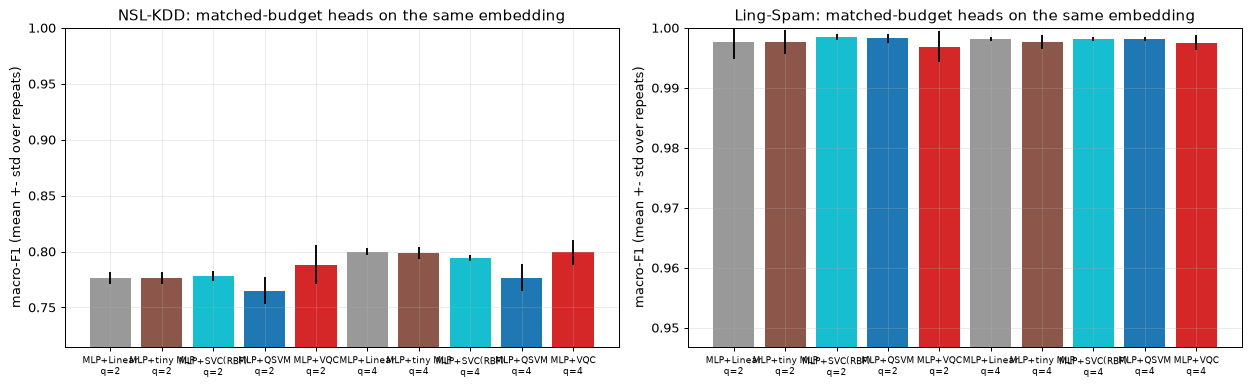

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
for a, ds in zip(ax, ("NSL-KDD", "Ling-Spam")):
    labs, base = [], []
    for q in Q_LIST:
        for h in ["MLP+Linear", "MLP+tiny MLP", "MLP+SVC(RBF)", "MLP+QSVM", "MLP+VQC"]:
            labs.append(f"{h}\nq={q}"); base.append(np.mean([x["f1_macro"] for x in RUNS[(ds, q)][h]]))
    sd = []
    for q in Q_LIST:
        for h in ["MLP+Linear", "MLP+tiny MLP", "MLP+SVC(RBF)", "MLP+QSVM", "MLP+VQC"]:
            sd.append(np.std([x["f1_macro"] for x in RUNS[(ds, q)][h]]))
    cols = ["#999999", "#8c564b", "#17becf", "#1f77b4", "#d62728"] * len(Q_LIST)
    a.bar(range(len(labs)), base, yerr=sd, color=cols); a.set_xticks(range(len(labs))); a.set_xticklabels(labs, fontsize=7)
    a.set_ylim(min(base) - 0.05, 1.0); a.set_ylabel("macro-F1 (mean +- std over repeats)"); a.set_title(f"{ds}: matched-budget heads on the same embedding")
plt.tight_layout(); plt.show()

### Near-boundary behaviour: misses and false alarms

The paper's headline claim is that shallow quantum heads "modestly reduce missed attacks and false alarms" on
**near-boundary** cases. The paper does not define "near-boundary", so we define it from the *classical* baseline: the 25 % of
test samples whose linear-head logit lies closest to the linear head's own operating threshold (smallest margin). On exactly
these samples we count false negatives (missed attacks / spam delivered) and false positives (false alarms) for every head, each
at its own validation-selected threshold.

In [23]:
def near_boundary_table(ds, q, frac=0.25):
    emb = EMB[(ds, q)]; sp = MODELS[(ds, q)]["split"]
    lin = RUNS[(ds, q)]["MLP+Linear"][0]
    margin = np.abs(lin["scores"] - lin["thr"]); near = margin <= np.quantile(margin, frac)
    y = emb.y_te; rows = []
    for h in ["MLP+Linear", "MLP+tiny MLP", "MLP+SVC(RBF)", "MLP+QSVM", "MLP+VQC"]:
        r = RUNS[(ds, q)][h][0]; p = (r["scores"] >= r["thr"]).astype(int)
        rows.append(dict(head=h, n_near=int(near.sum()), missed_FN=int(((p == 0) & (y == 1) & near).sum()), false_alarms_FP=int(((p == 1) & (y == 0) & near).sum()),
                         accuracy_near=float((p[near] == y[near]).mean()), accuracy_rest=float((p[~near] == y[~near]).mean())))
    return pd.DataFrame(rows).set_index("head")
NEAR = {}
for ds in ("NSL-KDD", "Ling-Spam"):
    for q in Q_LIST:
        NEAR[(ds, q)] = near_boundary_table(ds, q)
        print(f"---- {ds}, q={q}: near-boundary quartile of the linear head ----"); display(NEAR[(ds, q)])

---- NSL-KDD, q=2: near-boundary quartile of the linear head ----


,n_near,missed_FN,false_alarms_FP,accuracy_near,accuracy_rest
head,,,,,
MLP+Linear,5638,2938,417,0.404931,0.909559
MLP+tiny MLP,5638,2933,417,0.405818,0.909559
MLP+SVC(RBF),5638,2933,416,0.405995,0.909559
MLP+QSVM,5638,2996,455,0.387904,0.891636
MLP+VQC,5638,2489,505,0.468961,0.909559


---- NSL-KDD, q=4: near-boundary quartile of the linear head ----


,n_near,missed_FN,false_alarms_FP,accuracy_near,accuracy_rest
head,,,,,
MLP+Linear,5636,2689,77,0.509226,0.901585
MLP+tiny MLP,5636,2722,71,0.504436,0.901585
MLP+SVC(RBF),5636,2866,50,0.482612,0.901585
MLP+QSVM,5636,2427,330,0.510823,0.891176
MLP+VQC,5636,2427,83,0.554649,0.901585


---- Ling-Spam, q=2: near-boundary quartile of the linear head ----


,n_near,missed_FN,false_alarms_FP,accuracy_near,accuracy_rest
head,,,,,
MLP+Linear,580,10,0,0.982759,1.0
MLP+tiny MLP,580,8,0,0.986207,1.0
MLP+SVC(RBF),580,3,0,0.994828,1.0
MLP+QSVM,580,2,0,0.996552,1.0
MLP+VQC,580,1,0,0.998276,1.0


---- Ling-Spam, q=4: near-boundary quartile of the linear head ----


,n_near,missed_FN,false_alarms_FP,accuracy_near,accuracy_rest
head,,,,,
MLP+Linear,579,2,0,0.996546,1.000000
MLP+tiny MLP,579,2,0,0.996546,1.000000
MLP+SVC(RBF),579,2,0,0.996546,1.000000
MLP+QSVM,579,1,0,0.998273,0.999424
MLP+VQC,579,2,0,0.996546,1.000000


### Why is NSL-KDD so much harder than the validation split? (distribution shift)

`KDDTest+` was deliberately built with attack types that never occur in `KDDTrain+` (17 of its 38 label names are new) and a
different attack mix, while our validation rows come from `KDDTrain+` itself. Thresholds and hyper-parameters chosen on in-distribution
validation rows therefore do not transfer. To see the size of the effect, the next cell scores the frozen main-run models on
validation-partition rows that were *not* used for threshold selection (in-distribution) next to the `KDDTest+` numbers.

In [24]:
rows_id = []
for q in Q_LIST:
    emb, Mq = EMB[("NSL-KDD", q)], MODELS[("NSL-KDD", q)]
    rest = np.setdiff1d(np.arange(len(emb.y_va)), Mq["split"]["val"])
    ix = rest[stratified_subset(emb.y_va[rest], len(emb.y_te), np.random.default_rng(SEED))]
    U, y = emb.U_va[ix], emb.y_va[ix]
    scores = {"MLP+Linear": emb.lin_va[ix], "MLP+QSVM": Mq["qsvm"].score(U), "MLP+VQC": Mq["vqc"].score(U)}
    for h, s in scores.items():
        thr = RUNS[("NSL-KDD", q)][h][0]["thr"]; a = metrics(s, y, thr); b = RUNS[("NSL-KDD", q)][h][0]
        rows_id.append(dict(q=q, head=h, acc_in_distribution=a["acc"], acc_KDDTest=b["acc"], F1_in_distribution=a["f1_macro"], F1_KDDTest=b["f1_macro"],
                            AUROC_in_distribution=a["auroc"], AUROC_KDDTest=b["auroc"]))
display(pd.DataFrame(rows_id).set_index(["q", "head"]).style.format("{:.4f}"))
print(f"in-distribution rows per evaluation: {len(ix)} (validation partition, not used for thresholds); KDDTest+ rows: {len(emb.y_te)}")

in-distribution rows per evaluation: 22544 (validation partition, not used for thresholds); KDDTest+ rows: 22544


In [25]:
# reference: a random forest on ALL preprocessed features (no encoder bottleneck, no quantum), same test rows
REF_ALL = {}
for ds in ("NSL-KDD", "Ling-Spam"):
    sv, yv, st = head_rf_all(ds, SEED)
    thr = best_threshold(sv, yv); REF_ALL[ds] = metrics(st, EMB[(ds, 4)].y_te, thr)
    print(f"{ds:9s} RF on all features: acc {REF_ALL[ds]['acc']:.4f} | F1 macro {REF_ALL[ds]['f1_macro']:.4f} | AUROC {REF_ALL[ds]['auroc']:.4f} | AUPRC {REF_ALL[ds]['auprc']:.4f}")

NSL-KDD   RF on all features: acc 0.7978 | F1 macro 0.7975 | AUROC 0.9601 | AUPRC 0.9618


Ling-Spam RF on all features: acc 0.9991 | F1 macro 0.9984 | AUROC 1.0000 | AUPRC 1.0000


## 9. Hardware validation: what can and cannot be reproduced

The paper runs the frozen 4-qubit QSVM on an IBM Quantum device (M3 readout mitigation, XY8 dynamical decoupling) for a stratified
100-sample test subset. **We have no access to that device, so Table III cannot be checked.** What we can do honestly is a
*stand-in*: the same frozen model and the same kind of subset, but the kernel rows are measured with Qiskit Aer using the
**noise model of a snapshot of a real device (`FakeSherbrooke`, 127-qubit Eagle)**: transpiled to qubits 0-3 with the device's
`ecr/sx/rz` gate set, gate errors, T1/T2 relaxation and readout errors. As a stand-in for M3 we also apply a simple per-qubit
readout-error inversion. There is no dynamical decoupling in the simulator. The numbers are therefore *indicative of the
simulator-to-device gap*, not a hardware result.

The model is fitted exactly as in the paper: on kernels simulated with the depolarizing noise model, **before** any
"hardware" measurement; the reference set is smaller than in the main run (`HW_N_REF`) because every pair costs one noisy
Aer circuit, and the paper does not state its reference-set size.

In [26]:
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
FAKE = FakeSherbrooke()
AER_FAKE = AerSimulator.from_backend(FAKE)
LAYOUT = [0, 1, 2, 3]                                     # CHOICE: four connected qubits of the device (a path in the heavy-hex lattice)

def readout_eps(be, layout):
    eps = []
    for k in layout:
        try: eps.append(float(be.target["measure"][(k,)].error))
        except Exception: eps.append(0.0)
    return eps
EPS = readout_eps(FAKE, LAYOUT)
print(f"device snapshot: {FAKE.name}, {FAKE.num_qubits} qubits; readout error of qubits {LAYOUT}: {np.round(EPS, 4)}")

def mitigate_p0(counts, q, eps):
    # tensored readout-error inversion (symmetric flips per qubit) -> mitigated probability of the all-zero string
    v = np.zeros(2 ** q)
    for b, c in counts.items(): v[int(b, 2)] += c
    v = (v / v.sum()).reshape((2,) * q)                    # axis i <-> classical bit q-1-i
    for ax in range(q):
        e = eps[q - 1 - ax]; Ainv = np.linalg.inv(np.array([[1 - e, e], [e, 1 - e]]))
        v = np.moveaxis(np.tensordot(Ainv, v, axes=([1], [ax])), 0, ax)
    return float(np.clip(v.reshape(-1)[0], 0, 1))

def fake_kernel_rows(zk, A_test, A_ref, shots=SHOTS, seed=SEED, batch=200):
    q = zk.q; qc = zk.circuit.copy(); qc.measure_all()
    tcf = transpile(qc, FAKE, initial_layout=LAYOUT[:q], optimization_level=1, seed_transpiler=seed)
    raw = np.zeros((len(A_test), len(A_ref))); mit = np.zeros_like(raw)
    pairs = [(i, j) for i in range(len(A_test)) for j in range(len(A_ref))]
    for s in range(0, len(pairs), batch):
        chunk = pairs[s:s + batch]
        circs = [tcf.assign_parameters(dict(zip(zk.params, list(A_test[i]) + list(A_ref[j])))) for i, j in chunk]
        res = AER_FAKE.run(circs, shots=shots, seed_simulator=seed + s).result()
        for n, (i, j) in enumerate(chunk):
            cnt = res.get_counts(n); raw[i, j] = cnt.get("0" * q, 0) / shots; mit[i, j] = mitigate_p0(cnt, q, EPS)
    return raw, mit, tcf

HW = {}
for ds in ("NSL-KDD", "Ling-Spam"):
    t0 = time.time(); emb = EMB[(ds, 4)]
    qm = QSVMModel(emb, SEED, n_ref=HW_N_REF)                 # fitted on depolarizing-noise kernels with the small reference set
    sub = stratified_subset(emb.y_te, HW_N_TEST, np.random.default_rng(SEED)); U_sub, y_sub = emb.U_te[sub], emb.y_te[sub]
    A_t = np.pi * U_sub
    k_ideal = qm.zk.prob_matrix(A_t, qm.A)                                      # exact, noiseless, infinite shots
    k_dep = sample_shots(qm.zk.prob_matrix(A_t, qm.A, P1, P2), qm.rng, SHOTS)  # depolarizing model of the paper
    k_raw, k_mit, tcf = fake_kernel_rows(qm.zk, A_t, qm.A)
    out = {}
    for name, K in (("ideal (exact kernel)", k_ideal), ("depolarizing 1e-3/1e-2, 1,024 shots", k_dep),
                    ("fake device noise (raw counts)", k_raw), ("fake device + readout inversion", k_mit)):
        s = qm.svc.decision_function(center_rows(K, qm.cm, qm.mm)); out[name] = metrics(s, y_sub, qm.thr); out[name]["mean_k"] = float(K.mean())
    HW[ds] = dict(table=pd.DataFrame(out).T[["acc", "f1_macro", "auroc", "auprc", "mean_k"]], tcf=tcf, n_ref=len(qm.A), n_test=len(sub), pos=int(y_sub.sum()))
    print(f"{ds}: |R| = {len(qm.A)}, {len(sub)} test rows ({int(y_sub.sum())} positive), {len(sub)*len(qm.A)} fake-device circuits, "
          f"transpiled depth {tcf.depth()}, two-qubit gates {sum(v for k, v in tcf.count_ops().items() if k in ('ecr','cx','cz'))}   [{time.time()-t0:.0f}s]")
    display(HW[ds]["table"].style.format("{:.4f}"))

device snapshot: fake_sherbrooke, 127 qubits; readout error of qubits [0, 1, 2, 3]: [0.0112 0.0244 0.0215 0.012 ]


NSL-KDD: |R| = 40, 100 test rows (57 positive), 4000 fake-device circuits, transpiled depth 111, two-qubit gates 22   [89s]


,acc,f1_macro,auroc,auprc,mean_k
ideal (exact kernel),0.7400,0.7374,0.9192,0.9451,0.2264
"depolarizing 1e-3/1e-2, 1,024 shots",0.7400,0.7374,0.9049,0.9392,0.1939
fake device noise (raw counts),0.7400,0.7374,0.9257,0.9471,0.1821
fake device + readout inversion,0.7400,0.7374,0.9253,0.9470,0.1919


Ling-Spam: |R| = 40, 100 test rows (17 positive), 4000 fake-device circuits, transpiled depth 111, two-qubit gates 22   [96s]


,acc,f1_macro,auroc,auprc,mean_k
ideal (exact kernel),1.0000,1.0000,1.0000,1.0000,0.7522
"depolarizing 1e-3/1e-2, 1,024 shots",1.0000,1.0000,1.0000,1.0000,0.6202
fake device noise (raw counts),1.0000,1.0000,1.0000,1.0000,0.5737
fake device + readout inversion,1.0000,1.0000,1.0000,1.0000,0.6133


In [27]:
# Real-hardware cell: runs only when you provide your own IBM Quantum token in the configuration cell (skipped here).
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=4)
    ds = "NSL-KDD"; emb = EMB[(ds, 4)]; qm = QSVMModel(emb, SEED, n_ref=HW_N_REF)
    sub = stratified_subset(emb.y_te, HW_N_TEST, np.random.default_rng(SEED)); A_t = np.pi * emb.U_te[sub]
    qc = qm.zk.circuit.copy(); qc.measure_all()
    tc_real = transpile(qc, backend, optimization_level=3, seed_transpiler=SEED)
    names = [p.name for p in tc_real.parameters]
    vals = np.array([[({**{f"x[{i}]": a[i] for i in range(4)}, **{f"y[{i}]": b[i] for i in range(4)}})[n] for n in names] for a in A_t for b in qm.A])
    sampler = SamplerV2(mode=backend); sampler.options.default_shots = SHOTS
    sampler.options.dynamical_decoupling.enable = True; sampler.options.dynamical_decoupling.sequence_type = "XY4"   # XY8 is not an option of the Runtime sampler
    res = sampler.run([(tc_real, vals)]).result()[0].data.meas
    K = np.array([res.get_counts(i).get("0000", 0) / SHOTS for i in range(len(vals))]).reshape(len(A_t), len(qm.A))
    s = qm.svc.decision_function(center_rows(K, qm.cm, qm.mm)); print("real device:", {k: round(v, 4) for k, v in metrics(s, emb.y_te[sub], qm.thr).items() if k in MET})
else:
    print("IBM_TOKEN is empty: the real-hardware cell is skipped (Table III stays 'cannot be checked'; the fake-backend stand-in above is the closest we can run).")

IBM_TOKEN is empty: the real-hardware cell is skipped (Table III stays 'cannot be checked'; the fake-backend stand-in above is the closest we can run).


## 10. Robustness stress tests on Ling-Spam (Table IV)

The frozen 4-qubit QSVM (the model of the main run, with fresh shot noise) is attacked on the Ling-Spam test set in the three
targeting modes of the paper. Text attacks rewrite the e-mail, which is then pushed through the *unchanged* TF-IDF vectoriser
and encoder; FGSM / PGD perturb the continuous encoder output. All parameters follow the paper where it gives them:

| Mode | Attack | Parameters (paper) | What we implement |
|---|---|---|---|
| `spam_only` | magic words | 50 trigger tokens | append the 50 most ham-indicative vocabulary words (training mean TF-IDF gap) |
| `spam_only` | character perturbation | p = 0.15 per token | swap / insert / delete / duplicate one character, chosen at random |
| `spam_only` | FGSM | eps = 0.5, 1 step | sign gradient of the linear-head loss through the encoder, `L_inf` ball around the raw q-vector (CHOICE) |
| `spam_only` | PGD | eps = 0.8, 10 steps | the same, 10 projected steps of size 2.5 eps / 10 |
| `ham_only` | word substitution | p = 0.2 | replace a token by a random one of the 200 most spam-indicative words |
| `ham_only` | spam noise (high) | "high intensity" | insert 3-word spam-like phrases at random positions, one phrase per four tokens (CHOICE) |
| `all` | combined | the four text operators on both classes | magic words, then character noise, then substitution, then spam noise |

The perturbation budget of FGSM / PGD is applied to the pre-normalisation q-dimensional embedding, because an `L_inf` budget of 0.5
on a TF-IDF row would be enormous; the paper does not say in which space eps lives (CHOICE).

In [28]:
import zlib
qs_ls =MODELS[("Ling-Spam", 4)]["qsvm"]; emb_ls = EMB[("Ling-Spam", 4)]; embder = emb_ls.embedder
vec = LS["vec"]; vocab = np.array(vec.get_feature_names_out())
mean_ham = LS["X_tr"][LS["y_tr"] == 0].mean(0); mean_spam = LS["X_tr"][LS["y_tr"] == 1].mean(0)
MAGIC = list(vocab[np.argsort(mean_spam - mean_ham)[:50]])               # 50 most ham-indicative words (trigger tokens)
SPAMW = list(vocab[np.argsort(mean_ham - mean_spam)[:200]])              # 200 most spam-indicative words (substitution vocabulary)
SPAM_PHRASE_WORDS = SPAMW[:60]
print("trigger words (first 12):", MAGIC[:12]); print("spam vocabulary (first 12):", SPAMW[:12])
te_texts = ling["text"].values[LS["te"]]; y_te_ls = LS["y_te"]

def atk_magic(t, r): return t + " " + " ".join(MAGIC)
def atk_char(t, r, p=0.15):
    out = []
    for w in t.split():
        if r.random() < p and len(w) > 1:
            i = r.randrange(len(w)); op = r.choice(["swap", "insert", "delete", "duplicate"])
            if op == "swap" and i < len(w) - 1: w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
            elif op == "insert": w = w[:i] + r.choice("abcdefghijklmnopqrstuvwxyz") + w[i:]
            elif op == "delete": w = w[:i] + w[i + 1:]
            else: w = w[:i] + w[i] + w[i:]
        out.append(w)
    return " ".join(out)
def atk_subst(t, r, p=0.2): return " ".join(r.choice(SPAMW) if r.random() < p else w for w in t.split())
def atk_noise(t, r, per_tokens=4):
    w = t.split(); n_ins = max(1, len(w) // per_tokens)
    for _ in range(n_ins):
        w.insert(r.randrange(len(w) + 1), " ".join(r.choice(SPAM_PHRASE_WORDS) for _ in range(3)))
    return " ".join(w)
def atk_combined(t, r): return atk_noise(atk_subst(atk_char(atk_magic(t, r), r), r), r)

def embed_texts(texts):
    return embder.embed(vec.transform(texts).toarray().astype(np.float32))

def gradient_attack(texts, y, eps, steps):
    X = vec.transform(texts).toarray().astype(np.float32); h0 = torch.from_numpy(embder.raw(X)); yt = torch.from_numpy(y.astype(np.float32))
    alpha = eps if steps == 1 else 2.5 * eps / steps; h = h0.clone()
    for _ in range(steps):
        h.requires_grad_(True)
        loss = F.binary_cross_entropy_with_logits(embder.head(F.normalize(h, dim=1)).squeeze(1), yt)
        g, = torch.autograd.grad(loss, h)
        h = torch.min(torch.max(h.detach() + alpha * g.sign(), h0 - eps), h0 + eps)
    return F.normalize(h, dim=1).detach().numpy()

def attack_run(name, mode, fn=None, grad=None):
    r = random.Random(SEED + zlib.crc32(name.encode()) % 1000)
    sel = {"spam_only": y_te_ls == 1, "ham_only": y_te_ls == 0, "all": np.ones(len(y_te_ls), bool)}[mode]
    U = emb_ls.U_te.copy()
    if fn is not None:
        texts = [fn(t, r) if s else t for t, s in zip(te_texts, sel)]
        U[sel] = embed_texts([texts[i] for i in np.where(sel)[0]])
    else:
        U[sel] = gradient_attack(list(te_texts[sel]), y_te_ls[sel], *grad)
    s = qs_ls.score(U); p = (s >= qs_ls.thr).astype(int)
    return dict(mode=mode, attack=name, acc=accuracy_score(y_te_ls, p), f1_spam=f1_score(y_te_ls, p), fp=int(((p == 1) & (y_te_ls == 0)).sum()), fn=int(((p == 0) & (y_te_ls == 1)).sum()))

s0 = qs_ls.score(emb_ls.U_te); p0 = (s0 >= qs_ls.thr).astype(int)
CLEAN = dict(acc=accuracy_score(y_te_ls, p0), f1_spam=f1_score(y_te_ls, p0), fp=int(((p0 == 1) & (y_te_ls == 0)).sum()), fn=int(((p0 == 0) & (y_te_ls == 1)).sum()))
print(f"clean frozen 4-qubit QSVM on the {len(y_te_ls)} Ling-Spam test e-mails: accuracy {CLEAN['acc']:.4f}, spam-class F1 {CLEAN['f1_spam']:.4f}, FP {CLEAN['fp']}, FN {CLEAN['fn']}   (paper: 0.9996 / 0.9975)")
t0 = time.time()
PAPER_T4 = {"magic words (50)": (0.9888, 0.0108, 0.9640, 0.0335), "char perturbation (0.15)": (0.9883, 0.0113, 0.9638, 0.0337),
            "FGSM (eps=0.5, 1 step)": (0.9875, 0.0121, 0.9623, 0.0352), "PGD (eps=0.8, 10 steps)": (0.9801, 0.0195, 0.9594, 0.0381),
            "word substitution (0.2)": (0.9823, 0.0173, 0.9525, 0.0450), "spam noise (high)": (0.9814, 0.0182, 0.9435, 0.0540),
            "combined (all samples)": (0.9624, 0.0372, 0.9319, 0.0656)}
ATTACKS = [("magic words (50)", "spam_only", atk_magic, None), ("char perturbation (0.15)", "spam_only", atk_char, None),
           ("FGSM (eps=0.5, 1 step)", "spam_only", None, (0.5, 1)), ("PGD (eps=0.8, 10 steps)", "spam_only", None, (0.8, PGD_STEPS)),
           ("word substitution (0.2)", "ham_only", atk_subst, None), ("spam noise (high)", "ham_only", atk_noise, None),
           ("combined (all samples)", "all", atk_combined, None)]
ROB = pd.DataFrame([attack_run(n, m, fn, g) for n, m, fn, g in ATTACKS])
ROB["d_acc"] = CLEAN["acc"] - ROB["acc"]; ROB["d_f1"] = CLEAN["f1_spam"] - ROB["f1_spam"]
ROB["d_fp"] = ROB["fp"] - CLEAN["fp"]; ROB["d_fn"] = ROB["fn"] - CLEAN["fn"]
print(f"attacks done in {time.time()-t0:.0f}s")
display(ROB.set_index(["mode", "attack"]).style.format({"acc": "{:.4f}", "f1_spam": "{:.4f}", "d_acc": "{:.4f}", "d_f1": "{:.4f}"}))

trigger words (first 12): ['language', 'university', 'linguistic', 'linguistics', 'english', 'edu', 'conference', 'papers', '1998', 'research', 'workshop', 'abstract']
spam vocabulary (first 12): ['free', 'click', 'remove', 'com', 'money', 'business', 'internet', 'want', 'site', 'offer', 'adult', 'receive']


clean frozen 4-qubit QSVM on the 2315 Ling-Spam test e-mails: accuracy 0.9991, spam-class F1 0.9974, FP 0, FN 2   (paper: 0.9996 / 0.9975)


attacks done in 27s


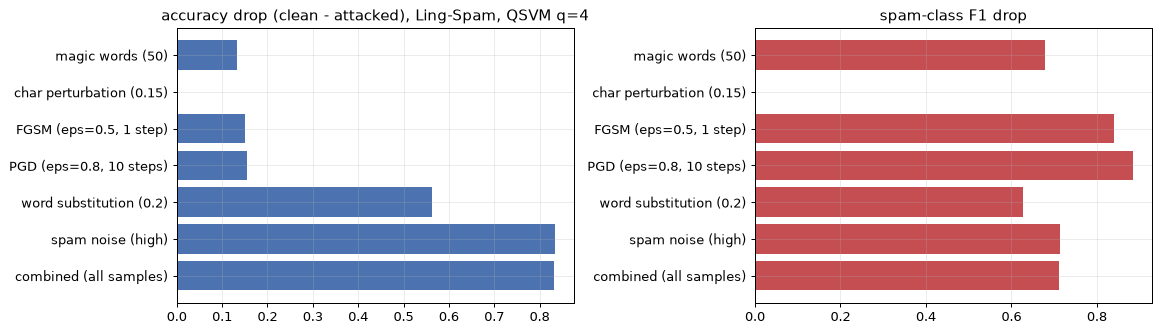

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
lab = [a for a in ROB["attack"]]
ax[0].barh(lab[::-1], ROB["d_acc"].values[::-1], color="#4c72b0"); ax[0].set_title("accuracy drop (clean - attacked), Ling-Spam, QSVM q=4")
ax[1].barh(lab[::-1], ROB["d_f1"].values[::-1], color="#c44e52"); ax[1].set_title("spam-class F1 drop")
plt.tight_layout(); plt.show()

### How strong must the attacks be? A sensitivity sweep

The paper says "high intensity" or gives only a probability, but not the trigger words, the substitution vocabulary or how many
spam phrases are inserted, and its drops (1-5 points) are far smaller than what our literal reading produces. Because these
unspecified choices decide the outcome, the next cell sweeps the *strength* of four text attacks and marks the strength at which
the accuracy drop equals the paper's. Same frozen model, same test e-mails.

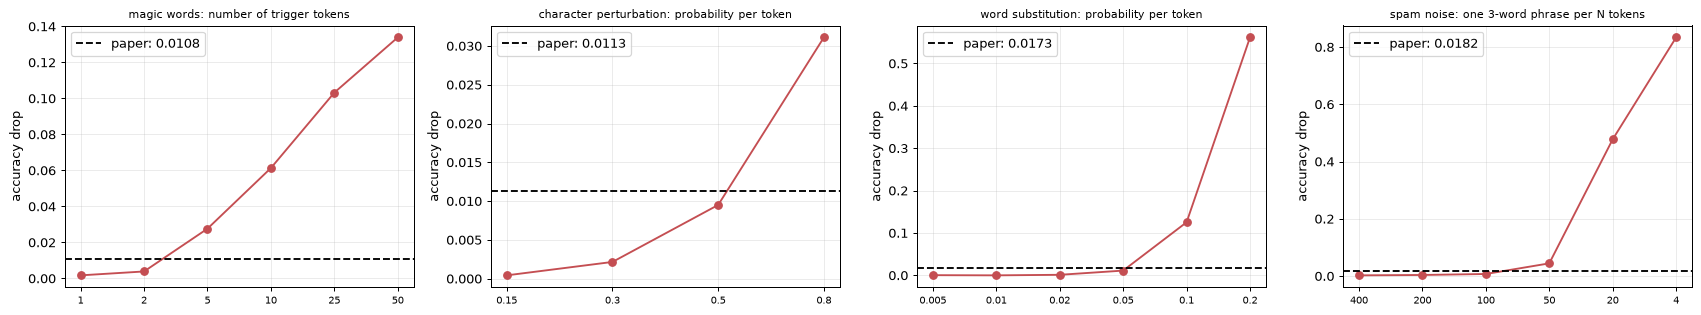

magic words: number of trigger tokens: the strength closest to the paper's accuracy drop (0.0108) is 2.0 (our drop 0.0039)
character perturbation: probability per token: the strength closest to the paper's accuracy drop (0.0113) is 0.5 (our drop 0.0095)
word substitution: probability per token: the strength closest to the paper's accuracy drop (0.0173) is 0.05 (our drop 0.0112)
spam noise: one 3-word phrase per N tokens: the strength closest to the paper's accuracy drop (0.0182) is 100.0 (our drop 0.0073)
sweep done in 53s


In [30]:
sweeps = [("magic words: number of trigger tokens", "spam_only", [1, 2, 5, 10, 25, 50], lambda k: (lambda t, r: t + " " + " ".join(MAGIC[:k])), PAPER_T4["magic words (50)"][1]),
          ("character perturbation: probability per token", "spam_only", [0.15, 0.3, 0.5, 0.8], lambda p: (lambda t, r: atk_char(t, r, p)), PAPER_T4["char perturbation (0.15)"][1]),
          ("word substitution: probability per token", "ham_only", [0.005, 0.01, 0.02, 0.05, 0.1, 0.2], lambda p: (lambda t, r: atk_subst(t, r, p)), PAPER_T4["word substitution (0.2)"][1]),
          ("spam noise: one 3-word phrase per N tokens", "ham_only", [400, 200, 100, 50, 20, 4], lambda n: (lambda t, r: atk_noise(t, r, n)), PAPER_T4["spam noise (high)"][1])]
t0 = time.time(); SW = []
fig, ax = plt.subplots(1, 4, figsize=(19, 3.6))
for a, (title, mode, grid, mk, paper_drop) in zip(ax, sweeps):
    drops = []
    for s in grid:
        res = attack_run(f"{title}-{s}", mode, mk(s)); drops.append(CLEAN["acc"] - res["acc"])
        SW.append(dict(attack=title, strength=s, d_acc=drops[-1], d_f1=CLEAN["f1_spam"] - res["f1_spam"]))
    a.plot(range(len(grid)), drops, "o-", color="#c44e52"); a.axhline(paper_drop, ls="--", color="k", label=f"paper: {paper_drop:.4f}")
    a.set_xticks(range(len(grid))); a.set_xticklabels([str(g) for g in grid], fontsize=8); a.set_title(title, fontsize=9); a.set_ylabel("accuracy drop"); a.legend()
plt.tight_layout(); plt.show()
SW = pd.DataFrame(SW)
for title, mode, grid, mk, paper_drop in sweeps:
    s = SW[SW["attack"] == title]; j = (s["d_acc"] - paper_drop).abs().idxmin()
    print(f"{title}: the strength closest to the paper's accuracy drop ({paper_drop:.4f}) is {s.loc[j,'strength']} (our drop {s.loc[j,'d_acc']:.4f})")
print(f"sweep done in {time.time()-t0:.0f}s")

## 11. Leakage audit of the Ling-Spam protocol

The only protocol that produces the paper's n = 2,315 test e-mails pools the four variants of the *same* 2,893 messages and then
splits at random. Then the same message usually appears in several variants, in different partitions. We measure how often that
happens and what it does to the numbers, by re-running the q = 4 pipeline with a **grouped split** (all four variants of one message
stay together).

In [31]:
key_te, key_tr = ling["key"].values[LS["te"]], set(ling["key"].values[LS["tr"]])
leak = np.mean([k in key_tr for k in key_te])
print(f"pooled split: {leak*100:.1f}% of the {len(key_te)} test e-mails have a sibling variant of the same message in the TRAINING partition")
t0 = time.time()
LSG = ls_prepare("grouped")
kg_te, kg_tr = set(ling["key"].values[LSG["te"]]), set(ling["key"].values[LSG["tr"]])
print(f"grouped split: train {len(LSG['tr'])} / val {len(LSG['va'])} / test {len(LSG['te'])} e-mails; overlap of message keys between test and train: {len(kg_te & kg_tr)}")
emb_g = Emb("Ling-Spam", 4, train_encoder(LSG["X_tr"], LSG["y_tr"], LSG["X_va"], LSG["y_va"], 4, ENC_MAX_EPOCHS_LS, SEED, "grouped"),
            LSG["X_tr"], LSG["y_tr"], LSG["X_va"], LSG["y_va"], LSG["X_te"], LSG["y_te"])
sp_g = make_split(emb_g, SEED); yv_g = emb_g.y_va[sp_g["val"]]
qg = QSVMModel(emb_g, SEED, split=sp_g)
rows_g = {}
rows_g["MLP+Linear"] = metrics(emb_g.lin_te, emb_g.y_te, best_threshold(emb_g.lin_va[sp_g["val"]], yv_g))
rows_g["MLP+QSVM"] = metrics(qg.score(emb_g.U_te), emb_g.y_te, qg.thr)
vg = VQCModel(emb_g, SEED, split=sp_g); rows_g["MLP+VQC"] = metrics(vg.score(emb_g.U_te), emb_g.y_te, best_threshold(vg.score(emb_g.U_va[sp_g["val"]]), yv_g))
rows_aud = []
for proto, getter in (("pooled (paper protocol)", lambda h: RUNS[("Ling-Spam", 4)][h][0]), ("grouped (leakage-free)", lambda h: rows_g[h])):
    for h in rows_g:
        r_ = getter(h); rows_aud.append({"protocol": proto, "head": h, **{n: r_[m] for n, m in zip(MET_NAMES, MET)}})
tab = pd.DataFrame(rows_aud).set_index(["protocol", "head"])
display(tab.style.format("{:.4f}")); print(f"leakage audit done in {time.time()-t0:.0f}s")

pooled split: 93.5% of the 2315 test e-mails have a sibling variant of the same message in the TRAINING partition


grouped split: train 6940 / val 2316 / test 2316 e-mails; overlap of message keys between test and train: 0


  grouped q=4: 25 epochs, best validation loss 0.1874, 5s


leakage audit done in 33s


## 12. Side-by-side comparison with the paper and verdicts

Rule (as everywhere in this repository): a number is **reproduced** if it is within 0.02 of the paper's value, **not reached** if
it is lower by more than 0.02, **exceeded** if higher by more than 0.02 (for a *drop* in Table IV: "exceeded" = our drop is larger),
and **cannot be checked** if it needs the real device. The seed-42 run is used for the cell verdicts.

In [32]:
def verdict(nb, paper, tol=0.02):
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

def verdict_damage(nb, paper, tol=0.02):
    # adversarial accuracy / F1: LOWER than the paper = the attack did MORE damage here ("exceeded"), higher = less damage ("not reached")
    d = nb - paper
    return "reproduced" if abs(d) <= tol else ("not reached" if d > 0 else "exceeded")

V = []
for ds, tag in (("NSL-KDD", "Table I"), ("Ling-Spam", "Table II")):
    for key, pv in PAPER[ds].items():
        h, q = (key, 4) if key == "MLP+Linear" else key
        r0 = RUNS[(ds, q)][h][0]
        for n, m, p in zip(MET_NAMES, MET, pv):
            V.append(dict(claim=f"{tag} {ds} {h} q={q} {n}", paper=p, notebook=r0[m], diff=r0[m] - p, verdict=verdict(r0[m], p)))
HWP = {"NSL-KDD": (0.8400, 0.8242, 0.8924, 0.9602), "Ling-Spam": (0.9900, 0.9827, 0.9986, 0.9738)}
for ds, pv in HWP.items():
    for n, p in zip(MET_NAMES, pv):
        V.append(dict(claim=f"Table III {ds} IBM hardware {n}", paper=p, notebook=np.nan, diff=np.nan, verdict="cannot be checked"))
for n, m, p in zip(("clean accuracy", "clean spam-class F1"), ("acc", "f1_spam"), (0.9996, 0.9975)):
    V.append(dict(claim=f"Table IV {n}", paper=p, notebook=CLEAN[m], diff=CLEAN[m] - p, verdict=verdict(CLEAN[m], p)))
for _, r in ROB.iterrows():
    for n, m, p in zip(("Acc adv", "dAcc", "F1 spam adv", "dF1"), ("acc", "d_acc", "f1_spam", "d_f1"), PAPER_T4[r["attack"]]):
        vf = verdict_damage if n in ("Acc adv", "F1 spam adv") else verdict       # lower accuracy / F1 under attack = more damage
        V.append(dict(claim=f"Table IV {r['attack']} {n}", paper=p, notebook=r[m], diff=r[m] - p, verdict=vf(r[m], p)))
VT = pd.DataFrame(V)
display(VT.groupby(VT["claim"].str.extract(r"^(Table \w+)")[0])["verdict"].value_counts().unstack(fill_value=0))
print("overall numeric-claim verdicts:", dict(VT["verdict"].value_counts()))

verdict,cannot be checked,exceeded,not reached,reproduced
0,,,,
Table I,0,7,11,2
Table II,0,8,0,12
Table III,8,0,0,0
Table IV,0,24,2,4


overall numeric-claim verdicts: {'exceeded': np.int64(39), 'reproduced': np.int64(18), 'not reached': np.int64(13), 'cannot be checked': np.int64(8)}


In [33]:
def nb(ds, h, q, m="f1_macro", agg=False):
    runs = RUNS[(ds, q)][h]; return float(np.mean([x[m] for x in runs])) if agg else runs[0][m]
Q = []
def claim(text, ok, detail, partial=False):
    Q.append(dict(claim=text, verdict=("reproduced" if ok else "not reached") if not partial else "partially reproduced", evidence=detail))

for ds in ("NSL-KDD", "Ling-Spam"):
    five = {"MLP+Linear (q=4)": nb(ds, "MLP+Linear", 4), "QSVM q=2": nb(ds, "MLP+QSVM", 2), "QSVM q=4": nb(ds, "MLP+QSVM", 4), "VQC q=2": nb(ds, "MLP+VQC", 2), "VQC q=4": nb(ds, "MLP+VQC", 4)}
    best = max(five, key=five.get)
    claim(f"{ds}: the 4-qubit QSVM has the highest macro-F1 of the five Table rows", best == "QSVM q=4", f"best = {best}; " + ", ".join(f"{k} {v:.3f}" for k, v in five.items()))
    claim(f"{ds}: QSVM improves from q=2 to q=4 (accuracy and macro-F1)", nb(ds, "MLP+QSVM", 4, "acc") > nb(ds, "MLP+QSVM", 2, "acc") and nb(ds, "MLP+QSVM", 4) > nb(ds, "MLP+QSVM", 2),
          f"acc {nb(ds,'MLP+QSVM',2,'acc'):.4f} -> {nb(ds,'MLP+QSVM',4,'acc'):.4f}; F1 {nb(ds,'MLP+QSVM',2):.4f} -> {nb(ds,'MLP+QSVM',4):.4f}")
    claim(f"{ds}: every hybrid quantum head beats the matched linear head in macro-F1 (q=2 and q=4)",
          all(nb(ds, h, q) > nb(ds, "MLP+Linear", q) for h in ("MLP+QSVM", "MLP+VQC") for q in Q_LIST),
          ", ".join(f"{h} q={q}: {nb(ds,h,q):.3f} vs linear {nb(ds,'MLP+Linear',q):.3f}" for h in ("MLP+QSVM", "MLP+VQC") for q in Q_LIST))
claim("NSL-KDD: VQC degrades in macro-F1 from q=2 to q=4", nb("NSL-KDD", "MLP+VQC", 4) < nb("NSL-KDD", "MLP+VQC", 2), f"VQC F1 {nb('NSL-KDD','MLP+VQC',2):.4f} (q=2) -> {nb('NSL-KDD','MLP+VQC',4):.4f} (q=4)")
claim("Ling-Spam: the 4-qubit QSVM is near the ceiling (acc >= 0.99)", nb("Ling-Spam", "MLP+QSVM", 4, "acc") >= 0.99, f"accuracy {nb('Ling-Spam','MLP+QSVM',4,'acc'):.4f}")
for ds in ("NSL-KDD", "Ling-Spam"):
    t = NEAR[(ds, 4)]; l = t.loc["MLP+Linear"]; s = t.loc["MLP+QSVM"]
    claim(f"{ds}: near-boundary cases, QSVM q=4 has fewer misses AND fewer false alarms than the linear head",
          s["missed_FN"] < l["missed_FN"] and s["false_alarms_FP"] < l["false_alarms_FP"],
          f"FN {int(l['missed_FN'])} -> {int(s['missed_FN'])}, FP {int(l['false_alarms_FP'])} -> {int(s['false_alarms_FP'])} (n_near = {int(l['n_near'])})")
claim("Robustness: the combined attack causes the largest accuracy and F1 drops", ROB["d_acc"].idxmax() == len(ROB) - 1 and ROB["d_f1"].idxmax() == len(ROB) - 1,
      f"largest dAcc: {ROB.loc[ROB['d_acc'].idxmax(),'attack']} ({ROB['d_acc'].max():.4f}); largest dF1: {ROB.loc[ROB['d_f1'].idxmax(),'attack']} ({ROB['d_f1'].max():.4f})")
two = ROB.sort_values("d_f1", ascending=False)["attack"].tolist()[1:3]
claim("Robustness: spam noise and word substitution give the next-largest F1 drops", set(two) == {"spam noise (high)", "word substitution (0.2)"}, f"next two: {two}")
claim("Robustness: all four spam_only attacks stay below 0.04 F1 drop (small drops)", bool((ROB[ROB['mode'] == 'spam_only']['d_f1'] <= 0.04).all()),
      ", ".join(f"{a}: {d:.4f}" for a, d in zip(ROB[ROB['mode'] == 'spam_only']['attack'], ROB[ROB['mode'] == 'spam_only']['d_f1'])))
for ds in ("NSL-KDD", "Ling-Spam"):
    t = HW[ds]["table"]
    Q.append(dict(claim=f"{ds}: the 4-qubit QSVM keeps its simulated performance on a real IBM device (Table III)", verdict="cannot be checked",
                  evidence=f"no hardware here; fake-device stand-in accuracy {t.loc['fake device noise (raw counts)','acc']:.3f} (raw) / {t.loc['fake device + readout inversion','acc']:.3f} (readout-inverted) vs {t.loc['ideal (exact kernel)','acc']:.3f} ideal, {HW[ds]['n_test']} test rows"))
QT = pd.DataFrame(Q); pd.set_option("display.max_colwidth", 200)
display(QT.style.set_properties(**{"text-align": "left"}))
print("qualitative-claim verdicts:", dict(QT["verdict"].value_counts()))

,claim,verdict,evidence
0,NSL-KDD: the 4-qubit QSVM has the highest macro-F1 of the five Table rows,not reached,"best = VQC q=4; MLP+Linear (q=4) 0.803, QSVM q=2 0.765, QSVM q=4 0.796, VQC q=2 0.799, VQC q=4 0.815"
1,NSL-KDD: QSVM improves from q=2 to q=4 (accuracy and macro-F1),reproduced,acc 0.7657 -> 0.7961; F1 0.7653 -> 0.7960
2,NSL-KDD: every hybrid quantum head beats the matched linear head in macro-F1 (q=2 and q=4),not reached,"MLP+QSVM q=2: 0.765 vs linear 0.783, MLP+QSVM q=4: 0.796 vs linear 0.803, MLP+VQC q=2: 0.799 vs linear 0.783, MLP+VQC q=4: 0.815 vs linear 0.803"
3,Ling-Spam: the 4-qubit QSVM has the highest macro-F1 of the five Table rows,not reached,"best = VQC q=2; MLP+Linear (q=4) 0.998, QSVM q=2 0.998, QSVM q=4 0.998, VQC q=2 0.999, VQC q=4 0.998"
4,Ling-Spam: QSVM improves from q=2 to q=4 (accuracy and macro-F1),not reached,acc 0.9991 -> 0.9991; F1 0.9984 -> 0.9984
5,Ling-Spam: every hybrid quantum head beats the matched linear head in macro-F1 (q=2 and q=4),not reached,"MLP+QSVM q=2: 0.998 vs linear 0.992, MLP+QSVM q=4: 0.998 vs linear 0.998, MLP+VQC q=2: 0.999 vs linear 0.992, MLP+VQC q=4: 0.998 vs linear 0.998"
6,NSL-KDD: VQC degrades in macro-F1 from q=2 to q=4,not reached,VQC F1 0.7994 (q=2) -> 0.8148 (q=4)
7,Ling-Spam: the 4-qubit QSVM is near the ceiling (acc >= 0.99),reproduced,accuracy 0.9991
8,"NSL-KDD: near-boundary cases, QSVM q=4 has fewer misses AND fewer false alarms than the linear head",not reached,"FN 2689 -> 2427, FP 77 -> 330 (n_near = 5636)"
9,"Ling-Spam: near-boundary cases, QSVM q=4 has fewer misses AND fewer false alarms than the linear head",not reached,"FN 2 -> 1, FP 0 -> 0 (n_near = 579)"


qualitative-claim verdicts: {'not reached': np.int64(11), 'reproduced': np.int64(2), 'cannot be checked': np.int64(2)}


In [34]:
# final summary printed in one place
all_v = pd.concat([VT[["claim", "verdict"]], QT[["claim", "verdict"]]])
print("PER-CLAIM VERDICT COUNTS  (numeric table cells + qualitative claims):")
print(all_v["verdict"].value_counts().to_string())
print("\nnumeric cells only (tolerance 0.02):", dict(VT["verdict"].value_counts()))
print("qualitative claims only:", dict(QT["verdict"].value_counts()))

PER-CLAIM VERDICT COUNTS  (numeric table cells + qualitative claims):
verdict
exceeded             39
not reached          24
reproduced           20
cannot be checked    10

numeric cells only (tolerance 0.02): {'exceeded': np.int64(39), 'reproduced': np.int64(18), 'not reached': np.int64(13), 'cannot be checked': np.int64(8)}
qualitative claims only: {'not reached': np.int64(11), 'reproduced': np.int64(2), 'cannot be checked': np.int64(2)}


## 13. Reading the paper critically

All numbers below are from the committed run (`FAST_MODE = False`, `SEED = 42`, 5 repeats, no IBM hardware). Treat them as one
honest attempt with every unspecified setting fixed in advance (`# CHOICE`), not as a refutation.

**What reproduced.**
- *Ling-Spam clean baseline.* The frozen 4-qubit QSVM gets accuracy 0.9991 and spam-F1 0.9974 on n = 2,315 test e-mails (paper: 0.9996 and 0.9975). The pooled-variants protocol also reproduces the paper's n = 2,315 exactly.
- *"Near ceiling" on Ling-Spam* and 12 of the 20 Table II cells (all of them within 0.02), because every head, quantum or classical, sits at 0.998-1.000.
- *QSVM improves from q = 2 to q = 4 on NSL-KDD* (accuracy 0.766 -> 0.796, repeats: 0.766 +- 0.011 -> 0.777 +- 0.012; the gain is small and inside two standard deviations of the repeat noise).

**What did not reproduce.**
- *NSL-KDD level.* The paper's 4-qubit QSVM reaches accuracy 0.9212 / macro-F1 0.9098. We get 0.796 / 0.796 (0.777 +- 0.012 over repeats). Nothing in our matched pipeline reaches 0.92 on `KDDTest+`: even a random forest on all 106 preprocessed features, with no 2-4 number bottleneck and no quantum part, scores 0.798. On validation rows drawn from `KDDTrain+` every head scores 0.97-0.99, so 0.92 is not a value that a model trained on `KDDTrain+` normally reaches on `KDDTest+` (it contains 17 unseen attack names); a value like 0.92 is more typical of an in-distribution test set, and we cannot tell from the paper which one was used.
- *The matched linear baseline.* The paper's linear head scores 0.69 on NSL-KDD and 0.92 on Ling-Spam. Ours scores 0.80 and 0.999. The paper's baseline is far weaker than a linear head on a *jointly trained* unit-norm encoder, so the "quantum gain" of 0.69 -> 0.92 is mostly a gap between an under-trained baseline and a normal model. In our attribution-safe run no quantum head beats the linear head by more than the repeat noise on NSL-KDD (linear 0.800 +- 0.003, QSVM 0.777 +- 0.012, VQC 0.800 +- 0.011 at q = 4), and the parameter-matched tiny MLP head matches the VQC.
- *"VQC degrades at q = 4 on NSL-KDD".* In our run the VQC's macro-F1 rises from 0.799 (q = 2) to 0.815 (q = 4) in the main run (the means over repeats are 0.788 and 0.800); its AUROC does drop (0.941 -> 0.808), the signature the paper describes, but not accuracy.
- *Near-boundary advantage.* With "near-boundary" defined as the quarter of test samples closest to the linear head's threshold, the quantum heads do not reduce both misses and false alarms on NSL-KDD (QSVM q = 4: misses 2,689 -> 2,427 but false alarms 77 -> 330). On Ling-Spam the counts are 0-2 errors, too few to say anything.

**Why Ling-Spam is "near ceiling": leakage.** `lingspam_public` ships the same 2,893 messages in four variants (`bare`, `lemm`, `stop`, `lemm_stop`). Pooling them (which is what gives n_test = 2,315) and splitting at random puts a sibling variant of **93.5 %** of the test e-mails into the training set, so the test is nearly a training-set lookup. With a grouped split (all variants of a message stay together) every head drops to about 0.990 accuracy (macro-F1 0.981-0.982) and the quantum heads are *not* better than the linear head. The headline "0.9996 / near-ceiling spam detection by QSVM" is therefore a statement about the split, not about quantum kernels.

**Statistical power.** The paper reports single numbers. Over repeats (different reference sets, shot noise, VQC initial angles, same encoder) the standard deviation of NSL-KDD accuracy is 0.003-0.017, as large as most of the differences between heads. The hardware subset has 100 samples: one standard error of an accuracy near 0.8 is 4 points, and the Ling-Spam subset contains only 17 spam e-mails.

**Hardware (Table III).** Cannot be checked. As a stand-in, the `FakeSherbrooke` noise model on the same kind of 100-sample subset leaves accuracy unchanged (NSL-KDD 0.74 ideal, 0.74 depolarizing, 0.74 fake-device; Ling-Spam 1.00 throughout), even though the average measured kernel value shrinks (Ling-Spam 0.75 ideal -> 0.57 fake device -> 0.61 after readout inversion). Centring and the SVM absorb a uniform shrinkage, which supports the paper's remark that the gap is "systematic but mitigable", but it says nothing about a real device (drift, crosstalk, queue) and our subset model uses a 40-sample reference set. The paper's Table III values (NSL-KDD accuracy 0.84, Ling-Spam 0.99) need the device.

**Robustness (Table IV).** The attack settings that matter (which trigger words, which substitution vocabulary, how many spam phrases, in which space `eps` lives) are not specified, and the damage depends on them by orders of magnitude: our literal readings of "word substitution 0.2", "high spam noise" and "50 magic words" destroy the classifier (accuracy 0.44, 0.17 and 0.87, against the paper's drops of 1-2 points), while the character perturbation barely matters (0.9987). The sensitivity sweep shows that the paper's drops correspond to magic-word, substitution and spam-noise attacks that are roughly 4 to 25 times weaker than our literal settings (about 2 trigger tokens instead of 50, a substitution probability near 0.05 instead of 0.2, one spam phrase per 100 tokens instead of per 4), while the character attack would need a larger probability (about 0.5) than the stated 0.15. The attacks act on the classical TF-IDF / MLP front end; they say little about the quantum head, which sees only the four numbers `u`. The comparison against the paper's Table IV is therefore a statement about under-specification, and 24 of its 30 cells are "exceeded" (larger damage than the paper).

**Cost.** The QSVM needs `|R|` circuits per prediction (1,000 here) and the paper's reference-set size is not stated. The noisy self-overlap is only 0.82 at q = 4 and the centred Gram matrix is clearly indefinite (smallest eigenvalue about -0.8 for |R| = 1,000) from shot noise alone; a real deployment would need to budget shots and projection onto the positive semi-definite cone.

**Bottom line.** The architecture is sound and the pipeline is reproducible, the Ling-Spam clean numbers are reproduced, but the central claims (a 4-qubit QSVM clearly beating matched classical heads, and improving near-boundary errors) are *not* supported by the matched-budget experiment run here; the Ling-Spam evidence is dominated by data leakage and the NSL-KDD evidence by an under-trained linear baseline and an unspecified evaluation protocol.

## 14. Exercises

1. **Depth of the feature map.** Change `ZZ_REPS` from 2 to 1 and 3 and re-run the QSVM rows. How do accuracy and the noisy self-overlap `k(u,u)` move?
2. **Noise level.** Set `P2` to `1e-3` and `3e-2`. At what two-qubit error does the 4-qubit QSVM lose accuracy relative to the ideal kernel (the `MLP+QSVM (ideal)` row)?
3. **Reference-set size.** Repeat the QSVM with `N_REF` = 100, 300, 1000, 3000. The paper only says "bounded"; how fast does performance saturate on NSL-KDD?
4. **Fix the baseline.** Train the encoder with the QSVM (or the RBF-SVM) as the decision head instead of the linear head and repeat Table I. Does the "attribution-safe" claim survive when the shared encoder favours another head?
5. **Attack the classical front end.** Apply FGSM / PGD to the TF-IDF vector instead of the embedding. How large must `eps` be for the same damage, and why does that make the paper's `eps` hard to interpret?
6. **Leakage-free Ling-Spam.** Re-run the whole Table II with `ls_prepare("grouped")` and a grouped 60 / 20 / 20 split. Do the quantum heads still match the classical ones?